# Rusty Bargain — Estimación del valor de mercado de vehículos usados

**Autora:** Belem Cisneros Díaz
**Fecha:** agosto de 2026
**Sprint 15 — Métodos numéricos**

---

Rusty Bargain, servicio de venta de coches de segunda mano, desarrolla una aplicación que
devuelve al usuario el valor de mercado estimado de su vehículo. El encargo consiste en
construir el modelo que produce esa estimación.

El cliente declara tres criterios de interés simultáneos: la calidad de la predicción, la
velocidad de la predicción y el tiempo requerido para el entrenamiento. El trabajo se
organiza alrededor de esos tres ejes.

## Resumen ejecutivo

## Resumen ejecutivo

El encargo solicita un modelo de valuación que atienda simultáneamente tres criterios: calidad de la
predicción, velocidad de la predicción y tiempo de entrenamiento. Las mediciones muestran que los tres
no admiten optimización conjunta. El modelo de mayor calidad es el más lento en predicción por lote;
el más rápido por lote es el más lento de entrenar; y el más rápido de entrenar es el de peor calidad
entre los métodos de potenciación.

**Se recomienda LightGBM** con seiscientos árboles, tasa de aprendizaje 0.05 y ciento veintisiete
hojas. Alcanza una RECM de 1 517.36 euros sobre el conjunto de prueba, frente a 2 218.66 euros del
proceso actual representado por una tabla de medianas por marca, modelo y antigüedad. La reducción es
de 701.30 euros, equivalente a 31.6 %.

El fundamento de la elección es que la única magnitud en la que CatBoost aventaja a LightGBM —una
latencia individual de 0.221 frente a 0.659 milisegundos— carece de relevancia operativa: la
diferencia de 0.438 milisegundos representa menos del uno por ciento de la latencia de red que una
aplicación interactiva ya incurre. La ventaja de LightGBM en calidad, de 40.61 euros frente a un
umbral de distinguibilidad de 19.13, sí es material.

A ello se suma el escalamiento. LightGBM presenta el exponente empírico más bajo de los cinco modelos
evaluados, con k igual a 0.058 en la relación T(n) = c · n^k. Su tiempo de entrenamiento crece 16 %
ante un aumento de 900 % en el número de registros, porque el método de histogramas busca los cortes
sobre doscientos cincuenta y cinco contenedores fijos y no sobre los registros. Extrapolado a diez
millones de anuncios, el reentrenamiento se situaría en trece segundos, frente a veintidós minutos del
bosque aleatorio.

**Dos salvedades condicionan la recomendación.** La primera es de uso: si el escenario principal fuese
la revaluación periódica del inventario completo en lugar de la consulta individual, CatBoost sería
preferible, dado que procesa el lote 4.4 veces más rápido. La segunda es de segmento: el modelo
presenta un error relativo de 166.8 % en el rango de 100 a 999 euros, que agrupa el 20.4 % del
conjunto de prueba. En ese tramo la estimación no es utilizable como referencia de precio, y se
recomienda que la aplicación muestre un rango en lugar de un valor puntual, o que omita la valuación
por debajo de un umbral. La causa es la métrica impuesta, que penaliza el cuadrado de la desviación y
concentra la capacidad del modelo en el extremo superior de la distribución.

La prueba de cordura exigida por el encargo se satisface con amplitud: los tres métodos de
potenciación superan a la regresión lineal en más de mil cien euros.

## 1. Encuadre del problema

### 1.1 Pregunta de negocio
Rusty Bargain necesita estimar el valor de mercado de un vehículo usado a partir de sus
características técnicas, su historial de matriculación y su equipamiento. La estimación
se entrega al usuario dentro de una aplicación, en el momento en que la solicita.

La decisión que soporta el modelo es el precio de referencia que la aplicación muestra al
usuario. No sustituye la negociación ni la valuación presencial: fija el punto de partida.

### 1.2 Variable objetivo

La variable objetivo es `Price`, el precio del vehículo expresado en euros. Es una
variable continua y no negativa, de modo que el problema es de regresión.

La decisión de modelar el precio en su escala original o en escala transformada queda
abierta hasta examinar su distribución en la sección 3.5.

### 1.3 Métrica primaria y criterio de éxito

La métrica primaria es la raíz del error cuadrático medio (RECM), impuesta por el encargo.
Se expresa en euros, la misma unidad que la variable objetivo, lo que permite leer el error
directamente en la escala del negocio.

    RECM = raíz cuadrada de la media de los cuadrados de las diferencias entre el precio
    observado y el precio predicho.

El criterio de éxito no se fija en abstracto. Se define como una mejora frente a tres
líneas base construidas en la sección 7, siendo la tabla de referencia por marca, modelo y
año el rival verdadero: es lo que un tasador haría sin modelo alguno.

### 1.4 Restricciones operativas

El encargo declara tres criterios de interés —calidad de la predicción, velocidad de la predicción
y tiempo de entrenamiento— sin asignar umbral numérico a ninguno. Se fijan los siguientes valores
de referencia, declarados como supuestos de diseño y no como requisitos del cliente.

**Latencia de predicción individual.** Se adopta un techo de cien milisegundos. El fundamento es
que una aplicación interactiva incurre en latencias de red de entre cincuenta y doscientos
milisegundos, de modo que un modelo por debajo de cien milisegundos resulta imperceptible frente
al costo de la comunicación. Todos los modelos evaluados cumplen ese techo con holgura.

**Tiempo de entrenamiento.** Se adopta un techo de quince minutos, correspondiente a un
reentrenamiento nocturno sobre inventario actualizado. Todos los modelos evaluados lo cumplen
sobre el conjunto actual; la extrapolación de la sección 11.3 muestra que dos de ellos dejarían de
cumplirlo a escala de diez millones de registros.

**Calidad.** No se fija umbral absoluto. El criterio es la superación de la tabla de referencia
construida en la sección 7.2, conforme se estableció en la sección 1.3.

### 1.5 Alcance

**Dentro del alcance.** Regresión lineal como prueba de cordura; árbol de decisión y
bosque aleatorio con ajuste de hiperparámetros; LightGBM, XGBoost y CatBoost con ajuste;
medición de tiempo de entrenamiento, de predicción por lote y de latencia individual;
análisis de escalamiento empírico; comparación conjunta de calidad y velocidad.

**Fuera del alcance.** Despliegue en producción, construcción de la interfaz de la
aplicación, servicio de predicción en línea, reentrenamiento automático, incorporación de
fuentes de datos externas y calibración de intervalos de confianza sobre el precio.

### 1.6 Supuestos declarados

**Uno. Año de referencia.** Se adopta 2016 como época de cálculo de la antigüedad, con fundamento
en el rango de las fechas de captura del conjunto, comprendido entre febrero y abril de ese año.
En operación real ese papel corresponde al año en curso.

**Dos. Escala de la variable objetivo.** El precio se modela en euros y no en escala logarítmica.
La métrica impuesta es la RECM en euros, y el ajuste sobre logaritmos minimizaría el error
relativo en lugar del absoluto, con un resultado peor bajo la métrica de evaluación. La decisión
se documenta en la sección 3.5 y su costo se cuantifica en la sección 12.4.

**Tres. Umbral inferior de precio válido.** Se establece en cien euros. Los registros por debajo
de esa cifra se consideran carentes de etiqueta utilizable.

**Cuatro. Rango admisible del año de matriculación.** Se establece entre 1900 y 2016.

**Cinco. Techo de potencia.** Se establece en mil caballos de vapor, magnitud ajena a un vehículo
de calle.

**Seis. Tratamiento de la duplicación.** Los registros coincidentes en características del
vehículo y precio se conservan por considerarse señal de mercado y no error de captura. La
consecuencia sobre la estimación se declara en la sección 6.2 y en la sección 14.

## 2. Datos

### 2.1 Origen y diccionario de variables

El conjunto proviene del archivo `car_data.csv`, entregado por el cliente. Contiene 354 369
registros y 16 columnas, con un peso de 41 MB en disco.

**Variable objetivo**

- `Price` — precio del vehículo, en euros.

**Características del vehículo**

- `VehicleType` — tipo de carrocería.
- `RegistrationYear` — año de matriculación.
- `Gearbox` — tipo de caja de cambios.
- `Power` — potencia, en caballos de vapor.
- `Model` — modelo del vehículo.
- `Mileage` — kilometraje, en kilómetros.
- `RegistrationMonth` — mes de matriculación.
- `FuelType` — tipo de combustible.
- `Brand` — marca del vehículo.
- `NotRepaired` — indica si el vehículo tiene daños no reparados.

**Metadatos del anuncio**

- `DateCrawled` — fecha en que el perfil se descargó de la base de datos.
- `DateCreated` — fecha de creación del perfil.
- `NumberOfPictures` — número de fotografías del anuncio.
- `PostalCode` — código postal del propietario del perfil.
- `LastSeen` — fecha de la última actividad del usuario.

La separación entre características del vehículo y metadatos del anuncio no es cosmética.
Los metadatos describen el proceso de publicación, no el bien valuado, y se someten a
revisión por riesgo de fuga en la sección 4.

### 2.2 Preparación del entorno

In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import lightgbm as lgb
import xgboost as xgb
import catboost
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

RANDOM_STATE = 12345
RUTA_DATOS = "../data/car_data.csv"
RUTA_FIGURAS = "../figures/"

colores = {
    "fondo": "#D5DBE7",
    "rejilla": "#5C5468",
    "texto": "#1F2224",
    "base": "#3A6878",
    "arboles": "#1A4A4F",
    "potenciacion": "#9A6A8C",
    "ganador": "#A8D8CC",
    "alerta": "#D4A8B4",
    "neutro": "#1E3130",
    "apoyo": "#4A88A4",
    "malva": "#B08AAE",
    "teal": "#3D7A8A",
    "blanco": "#FFFFFF",
}

plt.rcParams["figure.facecolor"] = colores["blanco"]
plt.rcParams["axes.facecolor"] = colores["fondo"]
plt.rcParams["axes.edgecolor"] = colores["rejilla"]
plt.rcParams["axes.labelcolor"] = colores["texto"]
plt.rcParams["text.color"] = colores["texto"]
plt.rcParams["xtick.color"] = colores["texto"]
plt.rcParams["ytick.color"] = colores["texto"]
plt.rcParams["grid.color"] = colores["rejilla"]
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"

print("Entorno preparado")
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("lightgbm", lgb.__version__)
print("xgboost", xgb.__version__)
print("catboost", catboost.__version__)

Entorno preparado
numpy 2.4.6
pandas 3.0.5
scikit-learn 1.9.0
lightgbm 4.7.0
xgboost 3.2.0
catboost 1.2.10


### 2.3 Carga

In [3]:
df = pd.read_csv(RUTA_DATOS)

nrows, ncols = df.shape
memoria_mb = df.memory_usage(deep=True).sum() / 1024**2

print("Registros:", f"{nrows:,}")
print("Columnas:", ncols)
print("Memoria:", f"{memoria_mb:.1f} MB")

Registros: 354,369
Columnas: 16
Memoria: 214.0 MB


### 2.4 Examen inicial

In [4]:
display(df.head())

print()
df.info()

print()
display(df.describe().T)

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,24/03/2016 11:52,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,24/03/2016 00:00,0,70435,07/04/2016 03:16
1,24/03/2016 10:58,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,24/03/2016 00:00,0,66954,07/04/2016 01:46
2,14/03/2016 12:52,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,14/03/2016 00:00,0,90480,05/04/2016 12:47
3,17/03/2016 16:54,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,17/03/2016 00:00,0,91074,17/03/2016 17:40
4,31/03/2016 17:25,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,31/03/2016 00:00,0,60437,06/04/2016 10:17



<class 'pandas.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DateCrawled        354369 non-null  str  
 1   Price              354369 non-null  int64
 2   VehicleType        316879 non-null  str  
 3   RegistrationYear   354369 non-null  int64
 4   Gearbox            334536 non-null  str  
 5   Power              354369 non-null  int64
 6   Model              334664 non-null  str  
 7   Mileage            354369 non-null  int64
 8   RegistrationMonth  354369 non-null  int64
 9   FuelType           321474 non-null  str  
 10  Brand              354369 non-null  str  
 11  NotRepaired        283215 non-null  str  
 12  DateCreated        354369 non-null  str  
 13  NumberOfPictures   354369 non-null  int64
 14  PostalCode         354369 non-null  int64
 15  LastSeen           354369 non-null  str  
dtypes: int64(7), str(9)
memory usage: 43.3 MB



,count,mean,std,min,25%,50%,75%,max
Price,354369.0,4416.656776,4514.158514,0.0,1050.0,2700.0,6400.0,20000.0
RegistrationYear,354369.0,2004.234448,90.227958,1000.0,1999.0,2003.0,2008.0,9999.0
Power,354369.0,110.094337,189.850405,0.0,69.0,105.0,143.0,20000.0
Mileage,354369.0,128211.172535,37905.341530,5000.0,125000.0,150000.0,150000.0,150000.0
RegistrationMonth,354369.0,5.714645,3.726421,0.0,3.0,6.0,9.0,12.0
NumberOfPictures,354369.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
PostalCode,354369.0,50508.689087,25783.096248,1067.0,30165.0,49413.0,71083.0,99998.0


## 3. Auditoría de calidad

### 3.1 Valores ausentes

In [5]:
ausentes = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "porcentaje": (df.isna().sum() / nrows * 100).round(2),
})

ausentes = ausentes[ausentes["ausentes"] > 0].sort_values("ausentes", ascending=False)

display(ausentes)

,ausentes,porcentaje
NotRepaired,71154,20.08
VehicleType,37490,10.58
FuelType,32895,9.28
Gearbox,19833,5.60
Model,19705,5.56


### 3.2 Registros duplicados

In [6]:
dup_completos = df.duplicated().sum()

columnas_vehiculo = [
    "Price", "VehicleType", "RegistrationYear", "Gearbox", "Power",
    "Model", "Mileage", "RegistrationMonth", "FuelType", "Brand", "NotRepaired",
]

dup_vehiculo = df.duplicated(subset=columnas_vehiculo).sum()

print("Duplicados en las 16 columnas:", f"{dup_completos:,}")
print("Duplicados en características del vehiculo y precio:", f"{dup_vehiculo:,}")
print("Proporcion sobre el total:", f"{dup_vehiculo / nrows * 100:.2f} %")

Duplicados en las 16 columnas: 262
Duplicados en características del vehiculo y precio: 27,543
Proporcion sobre el total: 7.77 %


### 3.3 Valores imposibles y fuera de rango

In [7]:
print("Rango de DateCrawled:", df["DateCrawled"].min(), "a", df["DateCrawled"].max())
print("Rango de DateCreated:", df["DateCreated"].min(), "a", df["DateCreated"].max())
print("Rango de LastSeen:", df["LastSeen"].min(), "a", df["LastSeen"].max())
print()

anomalias = {
    "Price igual a 0": (df["Price"] == 0).sum(),
    "Price menor a 100": (df["Price"] < 100).sum(),
    "RegistrationYear anterior a 1900": (df["RegistrationYear"] < 1900).sum(),
    "RegistrationYear posterior a 2016": (df["RegistrationYear"] > 2016).sum(),
    "Power igual a 0": (df["Power"] == 0).sum(),
    "Power mayor a 1000": (df["Power"] > 1000).sum(),
    "RegistrationMonth igual a 0": (df["RegistrationMonth"] == 0).sum(),
}

resumen = pd.DataFrame({
    "registros": pd.Series(anomalias),
})
resumen["porcentaje"] = (resumen["registros"] / nrows * 100).round(2)

display(resumen)

Rango de DateCrawled: 01/04/2016 00:06 a 31/03/2016 23:58
Rango de DateCreated: 01/02/2016 00:00 a 31/03/2016 00:00
Rango de LastSeen: 01/04/2016 00:15 a 31/03/2016 23:54



,registros,porcentaje
Price igual a 0,10772,3.04
Price menor a 100,13314,3.76
RegistrationYear anterior a 1900,66,0.02
RegistrationYear posterior a 2016,14530,4.10
Power igual a 0,40225,11.35
Power mayor a 1000,302,0.09
RegistrationMonth igual a 0,37352,10.54


### 3.4 Cardinalidad de las variables categóricas

In [8]:
columnas_categoricas = ["VehicleType", "Gearbox", "Model", "FuelType", "Brand", "NotRepaired"]

cardinalidad = pd.DataFrame({
    "valores_unicos": [df[col].nunique() for col in columnas_categoricas],
}, index=columnas_categoricas).sort_values("valores_unicos", ascending=False)

display(cardinalidad)

print()
for col in ["VehicleType", "Gearbox", "FuelType", "NotRepaired"]:
    print(col, "->", sorted(df[col].dropna().unique().tolist()))

,valores_unicos
Model,250
Brand,40
VehicleType,8
FuelType,7
Gearbox,2
NotRepaired,2



VehicleType -> ['bus', 'convertible', 'coupe', 'other', 'sedan', 'small', 'suv', 'wagon']
Gearbox -> ['auto', 'manual']
FuelType -> ['cng', 'electric', 'gasoline', 'hybrid', 'lpg', 'other', 'petrol']
NotRepaired -> ['no', 'yes']


### 3.5 Distribución de la variable objetivo

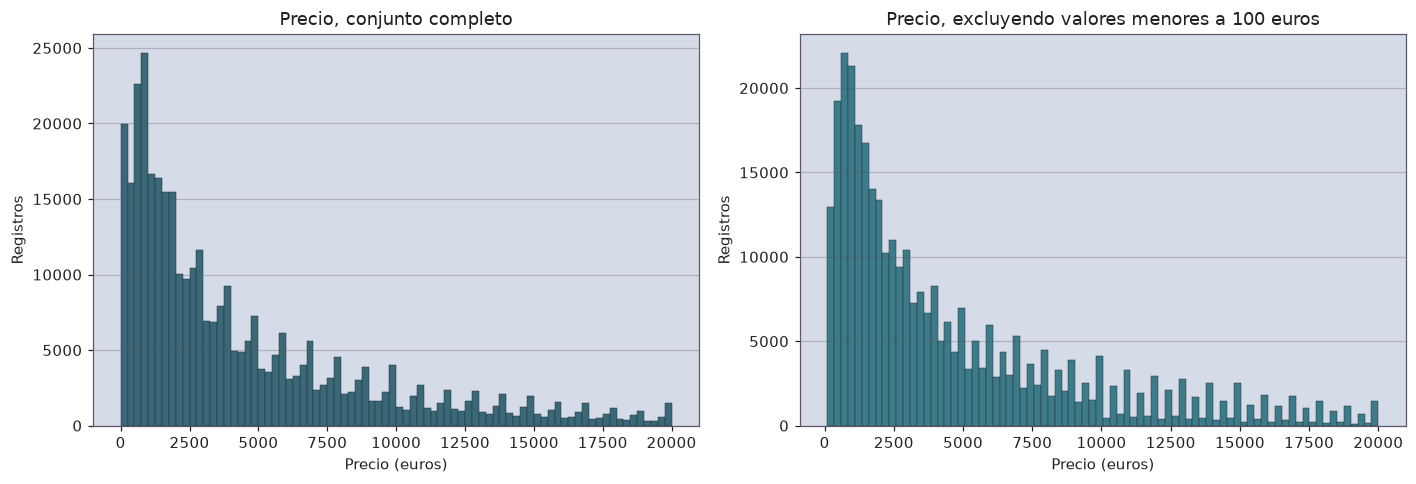

Asimetria del precio completo: 1.431
Asimetria excluyendo menores a 100: 1.408
Registros con precio igual al maximo de 20000: 268


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df["Price"], bins=80, color=colores["base"], edgecolor=colores["neutro"], linewidth=0.3)
axes[0].set_title("Precio, conjunto completo")
axes[0].set_xlabel("Precio (euros)")
axes[0].set_ylabel("Registros")
axes[0].grid(True, axis="y")

precio_valido = df.loc[df["Price"] >= 100, "Price"]
axes[1].hist(precio_valido, bins=80, color=colores["teal"], edgecolor=colores["neutro"], linewidth=0.3)
axes[1].set_title("Precio, excluyendo valores menores a 100 euros")
axes[1].set_xlabel("Precio (euros)")
axes[1].set_ylabel("Registros")
axes[1].grid(True, axis="y")

plt.tight_layout()
plt.show()

print("Asimetria del precio completo:", round(df["Price"].skew(), 3))
print("Asimetria excluyendo menores a 100:", round(precio_valido.skew(), 3))
print("Registros con precio igual al maximo de 20000:", f"{(df['Price'] == 20000).sum():,}")

### 3.6 Dictamen de la auditoría

La auditoría sobre 354 369 registros arroja cinco hallazgos con consecuencia directa sobre
la preparación.

**Uno. Columna sin información.** `NumberOfPictures` tiene media y desviación estándar
iguales a cero en la totalidad del conjunto: es constante. No aporta capacidad de
discriminación y se elimina.

**Dos. Ausencias concentradas en las categóricas.** Cinco columnas presentan valores
ausentes: `NotRepaired` con 20.08 %, `VehicleType` con 10.58 %, `FuelType` con 9.28 %,
`Gearbox` con 5.60 % y `Model` con 5.56 %. Ninguna baja del 5 %, y eliminar los registros
afectados costaría cerca de un tercio del conjunto. Se imputan como categoría explícita.

**Tres. Ausencias codificadas como números.** `Power` registra 40 225 valores en cero
(11.35 %) y `RegistrationMonth` registra 37 352 (10.54 %). Un motor de cero caballos y un
mes cero no existen: ambos son ausencias disfrazadas de dato numérico. Se convierten a
valor ausente antes de cualquier tratamiento.

**Cuatro. Valores fuera de rango físico.** El año de matriculación va de 1000 a 9999, con
14 530 registros posteriores a 2016 y 66 anteriores a 1900. Dado que la captura ocurrió
entre febrero y abril de 2016, un vehículo matriculado después de esa fecha es imposible.
`Power` supera los 1 000 caballos en 302 registros, cifra ajena a un vehículo de calle.

**Cinco. Precio nulo.** 10 772 registros tienen precio igual a cero y 13 314 por debajo de
100 euros. Sin etiqueta válida no hay nada que aprender ni contra qué evaluar. Se eliminan.

**Duplicación.** 262 filas son idénticas en las 16 columnas y corresponden a repeticiones de
captura; se eliminan. Distinto es el caso de los 27 543 registros (7.77 %) que coinciden en
características del vehículo y precio: son anuncios de vehículos equivalentes, y el precio
repetido constituye señal de mercado. No se eliminan, pero quedan anotados como riesgo de
contaminación entre particiones, que se atiende en la sección 6.

**Cardinalidad.** Las seis variables categóricas suman 309 valores distintos, de los cuales
250 pertenecen a `Model` y 40 a `Brand`. La codificación indicadora eleva la matriz de
diseño de diez a más de trescientas columnas, mientras que LightGBM y CatBoost operan sobre
las diez originales. La diferencia condiciona directamente el tiempo de entrenamiento y se
mide en la sección 10.

**Distribución del objetivo.** El precio presenta asimetría positiva de 1.431, que se
mantiene en 1.408 al excluir los valores por debajo de 100 euros: el sesgo es propiedad del
mercado, no artefacto de los ceros. Se observan concentraciones en cifras redondas, efecto
del redondeo del vendedor. Solo 268 registros alcanzan el máximo de 20 000 euros, de modo
que el recorte superior no distorsiona la cola.

**Tipo incorrecto en las fechas.** `DateCrawled`, `DateCreated` y `LastSeen` se leyeron como
cadenas de texto. La comparación entre ellas es alfabética y no cronológica, motivo por el
cual el mínimo aparente resulta posterior al máximo. Se convierten a tipo fecha en la
sección 5.

## 4. Riesgo de fuga de información

### 4.1 Lista de verificación por columna

El criterio de evaluación es operativo: se pregunta qué información posee la aplicación en
el instante en que el usuario solicita la valuación de su vehículo. Toda variable generada
con posterioridad a ese instante queda descartada, con independencia de su poder predictivo.

**`DateCrawled` — fecha de descarga del perfil.** Registra cuándo el recolector extrajo el
anuncio de la base de datos. Describe el proceso de captura, no el vehículo. En el momento
de la consulta no existe anuncio alguno que descargar. **Excluida.**

**`DateCreated` — fecha de creación del perfil.** Marca el momento en que el vendedor
publicó el anuncio. El usuario que consulta la aplicación no ha publicado nada: pide una
valuación previa a la decisión de vender. **Excluida.**

**`LastSeen` — última actividad del usuario.** Es la variable de mayor riesgo. La distancia
entre `DateCreated` y `LastSeen` mide cuánto tiempo permaneció activo el anuncio, magnitud
que se relaciona con la velocidad de venta y, por tanto, con el acierto del precio pedido.
Es información posterior al hecho que se pretende predecir. **Excluida.**

**`NumberOfPictures` — número de fotografías.** Constante en todo el conjunto, según la
sección 3.6. Sin variación no hay información. **Excluida por ausencia de contenido, no por
fuga.**

**`PostalCode` — código postal del propietario.** El usuario conoce su código postal al
momento de la consulta, de modo que no constituye fuga. Es una variable legítima que captura
efectos geográficos de mercado. Se conserva, con la salvedad de que su naturaleza es
categórica pese a estar almacenada como número: los códigos vecinos no guardan relación
ordinal con el precio.

**Características del vehículo.** `VehicleType`, `RegistrationYear`, `Gearbox`, `Power`,
`Model`, `Mileage`, `RegistrationMonth`, `FuelType`, `Brand` y `NotRepaired` describen
propiedades físicas y documentales del bien. Todas son conocidas por el propietario antes de
cualquier publicación. **Conservadas.**

### 4.2 Dictamen y columnas excluidas

Se excluyen cuatro columnas: `DateCrawled`, `DateCreated`, `LastSeen` y `NumberOfPictures`.
Las tres primeras por fuga temporal, la cuarta por ser constante.

Queda una excepción de uso. `DateCrawled` no ingresa como característica, pero su año sí se
emplea como época de referencia para derivar la antigüedad del vehículo:

    antigüedad = 2016 − RegistrationYear

El uso es admisible porque el año de referencia entra como constante conocida, no como dato
proveniente del anuncio. En operación, ese papel lo cumpliría el año en curso.

El conjunto de trabajo queda entonces en diez características más la variable objetivo.

## 5. Preparación de los datos

### 5.1 Reglas de limpieza

In [11]:
datos = df.copy()

registros_inicio = len(datos)
bitacora = []

datos = datos.drop_duplicates()
bitacora.append(("Eliminacion de duplicados completos", registros_inicio - len(datos), len(datos)))

columnas_excluidas = ["DateCrawled", "DateCreated", "LastSeen", "NumberOfPictures"]
datos = datos.drop(columns=columnas_excluidas)

previo = len(datos)
datos.loc[datos["Power"] == 0, "Power"] = np.nan
datos.loc[datos["RegistrationMonth"] == 0, "RegistrationMonth"] = np.nan
bitacora.append(("Ceros convertidos a ausente en Power y RegistrationMonth", 0, len(datos)))

previo = len(datos)
datos = datos[datos["Price"] >= 100]
bitacora.append(("Precio menor a 100 euros", previo - len(datos), len(datos)))

previo = len(datos)
datos = datos[(datos["RegistrationYear"] >= 1900) & (datos["RegistrationYear"] <= 2016)]
bitacora.append(("Ano de matriculacion fuera de 1900 a 2016", previo - len(datos), len(datos)))

previo = len(datos)
datos = datos[(datos["Power"].isna()) | (datos["Power"] <= 1000)]
bitacora.append(("Potencia superior a 1000 CV", previo - len(datos), len(datos)))

datos = datos.reset_index(drop=True)

resumen_limpieza = pd.DataFrame(bitacora, columns=["regla", "registros_eliminados", "registros_restantes"])
display(resumen_limpieza)

print()
print("Registros iniciales:", f"{registros_inicio:,}")
print("Registros finales:", f"{len(datos):,}")
print("Perdida total:", f"{registros_inicio - len(datos):,}", f"({(registros_inicio - len(datos)) / registros_inicio * 100:.2f} %)")
print("Columnas restantes:", datos.shape[1])

,regla,registros_eliminados,registros_restantes
0,Eliminacion de duplicados completos,262,354107
1,Ceros convertidos a ausente en Power y Registr...,0,354107
2,Precio menor a 100 euros,13311,340796
3,Ano de matriculacion fuera de 1900 a 2016,13729,327067
4,Potencia superior a 1000 CV,259,326808



Registros iniciales: 354,369
Registros finales: 326,808
Perdida total: 27,561 (7.78 %)
Columnas restantes: 12


### 5.2 Tratamiento de valores ausentes

In [12]:
ausentes_post = pd.DataFrame({
    "ausentes": datos.isna().sum(),
    "porcentaje": (datos.isna().sum() / len(datos) * 100).round(2),
})
ausentes_post = ausentes_post[ausentes_post["ausentes"] > 0].sort_values("ausentes", ascending=False)

print("Ausentes tras la limpieza")
display(ausentes_post)

for col in columnas_categoricas:
    datos[col] = datos[col].fillna("desconocido")

print()
print("Ausentes tras la imputacion de categoricas")
display(datos.isna().sum()[datos.isna().sum() > 0])

Ausentes tras la limpieza


,ausentes,porcentaje
NotRepaired,58332,17.85
Power,31606,9.67
RegistrationMonth,28212,8.63
FuelType,23069,7.06
VehicleType,18881,5.78
Model,15139,4.63
Gearbox,14588,4.46



Ausentes tras la imputacion de categoricas


Power                31606
RegistrationMonth    28212
dtype: int64

### 5.3 Ingeniería de características

In [13]:
ANIO_REFERENCIA = 2016

datos["antiguedad"] = ANIO_REFERENCIA - datos["RegistrationYear"]
datos["potencia_ausente"] = datos["Power"].isna().astype(int)
datos["mes_ausente"] = datos["RegistrationMonth"].isna().astype(int)

print("Antiguedad")
display(datos["antiguedad"].describe().to_frame().T)

print()
print("Indicadores de ausencia")
print("potencia_ausente en 1:", f"{datos['potencia_ausente'].sum():,}")
print("mes_ausente en 1:", f"{datos['mes_ausente'].sum():,}")

print()
print("Precio medio segun potencia_ausente")
display(datos.groupby("potencia_ausente")["Price"].agg(["count", "mean", "median"]).round(1))

print("Precio medio segun mes_ausente")
display(datos.groupby("mes_ausente")["Price"].agg(["count", "mean", "median"]).round(1))

Antiguedad


,count,mean,std,min,25%,50%,75%,max
antiguedad,326808.0,13.374572,6.860465,0.0,9.0,13.0,17.0,106.0



Indicadores de ausencia
potencia_ausente en 1: 31,606
mes_ausente en 1: 28,212

Precio medio segun potencia_ausente


,count,mean,median
potencia_ausente,,,
0,295202,4874.0,3200.0
1,31606,2477.2,1300.0


Precio medio segun mes_ausente


,count,mean,median
mes_ausente,,,
0,298596,4870.3,3200.0
1,28212,2227.3,1111.0


### 5.4 Codificación de variables categóricas

In [14]:
caracteristicas = [
    "VehicleType", "Gearbox", "Power", "Model", "Mileage",
    "RegistrationMonth", "FuelType", "Brand", "NotRepaired",
    "antiguedad", "potencia_ausente", "mes_ausente",
]

X = datos[caracteristicas].copy()
y = datos["Price"].copy()

X_arboles = X.copy()
for col in columnas_categoricas:
    X_arboles[col] = X_arboles[col].astype("category")

X_ohe = X.copy()
mediana_power = X_ohe["Power"].median()
mediana_mes = X_ohe["RegistrationMonth"].median()
X_ohe["Power"] = X_ohe["Power"].fillna(mediana_power)
X_ohe["RegistrationMonth"] = X_ohe["RegistrationMonth"].fillna(mediana_mes)
X_ohe = pd.get_dummies(X_ohe, columns=columnas_categoricas, drop_first=True)

print("Codificacion nativa para LightGBM y CatBoost")
print("Dimensiones:", X_arboles.shape)
print("Memoria:", f"{X_arboles.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

print()
print("Codificacion indicadora para XGBoost y modelos de scikit-learn")
print("Dimensiones:", X_ohe.shape)
print("Memoria:", f"{X_ohe.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

print()
print("Factor de expansion en columnas:", round(X_ohe.shape[1] / X_arboles.shape[1], 1))
print("Mediana usada para imputar Power:", mediana_power)
print("Mediana usada para imputar RegistrationMonth:", mediana_mes)
print("Ausentes restantes en X_ohe:", int(X_ohe.isna().sum().sum()))

Codificacion nativa para LightGBM y CatBoost
Dimensiones: (326808, 12)
Memoria: 17.2 MB

Codificacion indicadora para XGBoost y modelos de scikit-learn
Dimensiones: (326808, 314)
Memoria: 111.0 MB

Factor de expansion en columnas: 26.2
Mediana usada para imputar Power: 111.0
Mediana usada para imputar RegistrationMonth: 6.0
Ausentes restantes en X_ohe: 0


### 5.5 Conjunto final

In [15]:
print("Caracteristicas conservadas:", len(caracteristicas))
for c in caracteristicas:
    print("  -", c)

print()
print("Columnas descartadas del conjunto original:")
for c in ["DateCrawled", "DateCreated", "LastSeen", "NumberOfPictures", "PostalCode", "RegistrationYear"]:
    print("  -", c)

print()
print("Filas en X_arboles:", f"{X_arboles.shape[0]:,}")
print("Filas en X_ohe:", f"{X_ohe.shape[0]:,}")
print("Filas en y:", f"{len(y):,}")
print("Coinciden:", X_arboles.shape[0] == X_ohe.shape[0] == len(y))

print()
print("Objetivo")
display(y.describe().to_frame().T.round(1))

Caracteristicas conservadas: 12
  - VehicleType
  - Gearbox
  - Power
  - Model
  - Mileage
  - RegistrationMonth
  - FuelType
  - Brand
  - NotRepaired
  - antiguedad
  - potencia_ausente
  - mes_ausente

Columnas descartadas del conjunto original:
  - DateCrawled
  - DateCreated
  - LastSeen
  - NumberOfPictures
  - PostalCode
  - RegistrationYear

Filas en X_arboles: 326,808
Filas en X_ohe: 326,808
Filas en y: 326,808
Coinciden: True

Objetivo


,count,mean,std,min,25%,50%,75%,max
Price,326808.0,4642.2,4546.7,100.0,1200.0,2950.0,6700.0,20000.0


El conjunto de trabajo queda en 326 808 registros y doce características, con `Price` como
objetivo. Se producen dos representaciones paralelas del mismo conjunto:

- **Codificación nativa**, de doce columnas y 17.2 MB, para LightGBM y CatBoost.
- **Codificación indicadora**, de 314 columnas y 111.0 MB, para XGBoost, la regresión lineal,
  el árbol de decisión y el bosque aleatorio.

El factor de expansión es de 26.2 en columnas y de 6.5 en memoria. La diferencia entre ambos
factores obedece a que las columnas indicadoras se almacenan como valores booleanos de un
byte, mientras que la representación categórica conserva el diccionario de etiquetas.

**Descarte de `RegistrationYear`.** La variable se sustituye por `antiguedad`, definida como
la diferencia entre el año de referencia y el año de matriculación. Ambas contienen
exactamente la misma información y su correlación es perfecta y negativa, de modo que
conservar las dos introduciría colinealidad exacta. Se retiene la derivada porque su
coeficiente en la regresión lineal admite lectura directa como pérdida de valor por año
transcurrido.

**Descarte de `PostalCode`.** La sección 4.1 la declaró libre de fuga, y en efecto lo está.
El motivo de su exclusión es distinto: se trata de una variable categórica almacenada como
entero, con cerca de ocho mil valores distintos. Tratarla como número induciría una relación
ordinal inexistente, pues los códigos contiguos no guardan proximidad de precio. Codificarla
de forma indicadora agregaría miles de columnas a una matriz que ya alcanza 314. Su
aprovechamiento correcto exigiría agregación regional o codificación por objetivo, ambas con
riesgo de fuga si se calculan antes de particionar. Queda registrada como línea de trabajo
futuro en la sección 14.

**Imputación aplicada.** En la representación indicadora, `Power` se imputa con su mediana de
111 CV y `RegistrationMonth` con su mediana de 6. Los indicadores `potencia_ausente` y
`mes_ausente` preservan la localización original de cada ausencia. En la representación
nativa los valores ausentes se conservan como tales, dado que ambas librerías aprenden la
dirección de ramificación para los nulos.

## 6. Protocolo experimental

### 6.1 Particiones

In [16]:
indices_train, indices_test = train_test_split(
    datos.index, test_size=0.25, random_state=RANDOM_STATE
)

X_arboles_train = X_arboles.loc[indices_train]
X_arboles_test = X_arboles.loc[indices_test]

X_ohe_train = X_ohe.loc[indices_train]
X_ohe_test = X_ohe.loc[indices_test]

y_train = y.loc[indices_train]
y_test = y.loc[indices_test]

print("Entrenamiento:", f"{len(indices_train):,}", f"({len(indices_train) / len(datos) * 100:.1f} %)")
print("Prueba:", f"{len(indices_test):,}", f"({len(indices_test) / len(datos) * 100:.1f} %)")

print()
print("Verificacion de identidad de indices entre representaciones")
print("Train:", X_arboles_train.index.equals(X_ohe_train.index))
print("Test:", X_arboles_test.index.equals(X_ohe_test.index))
print("Sin traslape:", len(set(indices_train) & set(indices_test)) == 0)

print()
print("Precio medio en entrenamiento:", f"{y_train.mean():.1f}")
print("Precio medio en prueba:", f"{y_test.mean():.1f}")
print("Diferencia:", f"{abs(y_train.mean() - y_test.mean()):.1f}", "euros")

Entrenamiento: 245,106 (75.0 %)
Prueba: 81,702 (25.0 %)

Verificacion de identidad de indices entre representaciones
Train: True
Test: True
Sin traslape: True

Precio medio en entrenamiento: 4642.4
Precio medio en prueba: 4641.5
Diferencia: 0.9 euros


### 6.2 Esquema de validación

In [17]:
N_PLIEGUES = 5

esquema_cv = KFold(n_splits=N_PLIEGUES, shuffle=True, random_state=RANDOM_STATE)


def recm(y_real, y_predicho):
    return float(np.sqrt(mean_squared_error(y_real, y_predicho)))


resultados = []

print("Esquema de validacion")
print("Pliegues:", N_PLIEGUES)
print("Barajado:", True)
print("Semilla:", RANDOM_STATE)
print("Registros por pliegue de validacion:", f"{len(indices_train) // N_PLIEGUES:,}")

print()
print("Prueba de la funcion recm")
print("Valor esperado 0.0 con prediccion perfecta:", recm(np.array([1.0, 2.0, 3.0]), np.array([1.0, 2.0, 3.0])))
print("Valor esperado 2.0 con error constante de 2:", recm(np.array([1.0, 2.0, 3.0]), np.array([3.0, 4.0, 5.0])))

Esquema de validacion
Pliegues: 5
Barajado: True
Semilla: 12345
Registros por pliegue de validacion: 49,021

Prueba de la funcion recm
Valor esperado 0.0 con prediccion perfecta: 0.0
Valor esperado 2.0 con error constante de 2: 2.0


### 6.3 Instrumento de medición de tiempos

La comparación entre modelos se realiza mediante validación cruzada de cinco pliegues sobre
el conjunto de entrenamiento, con barajado previo y semilla fija. El conjunto de prueba
permanece intacto hasta la sección 12.

**Por qué no basta una partición única.** Una sola división en entrenamiento y validación
produce una estimación con varianza propia, atribuible al azar del reparto y no al modelo.
Diferencias pequeñas entre dos algoritmos pueden invertirse al cambiar la semilla. La
validación cruzada entrega no solo un promedio más estable sobre cinco estimaciones
independientes, sino la desviación entre pliegues, que es la magnitud contra la cual se juzga
si una diferencia observada es real.

**Regla de decisión, fijada antes de conocer resultados.** Si la diferencia de RECM entre dos
modelos resulta menor que la desviación estándar entre pliegues del mejor de ellos, ambos se
declaran equivalentes en calidad y la elección se resuelve por el segundo criterio del
encargo: la velocidad. Entre modelos equivalentes en calidad y velocidad, se prefiere el de
menor complejidad.

**Riesgo de contaminación entre particiones.** La sección 3.2 registró 27 543 registros
coincidentes en características del vehículo y precio, equivalentes al 7.77 % del conjunto
original. Al no eliminarse, existe la posibilidad de que ejemplares equivalentes queden
repartidos entre pliegues, lo que favorecería a los modelos con mayor capacidad de
memorización. El efecto aplica por igual a todos los modelos comparados, de modo que no
altera el orden relativo, pero sí implica que las cifras absolutas de RECM constituyen una
estimación optimista. Se declara como limitación en la sección 14.

**Métrica.** La RECM se calcula como la raíz cuadrada del error cuadrático medio, de forma
explícita, sin depender de argumentos cuya disponibilidad varía entre versiones de
scikit-learn. La función se verificó contra dos casos de valor conocido: predicción perfecta,
que arroja cero, y error constante de dos unidades, que arroja dos.

In [18]:
def evaluar_modelo(nombre, constructor, X, y, cv=esquema_cv, n_latencia=100, registrar=True):
    recms = []
    tiempos_entrenamiento = []
    tiempos_prediccion = []
    modelo = None

    for idx_tr, idx_val in cv.split(X):
        X_tr, X_val = X.iloc[idx_tr], X.iloc[idx_val]
        y_tr, y_val = y.iloc[idx_tr], y.iloc[idx_val]

        modelo = constructor()

        inicio = time.perf_counter()
        modelo.fit(X_tr, y_tr)
        tiempos_entrenamiento.append(time.perf_counter() - inicio)

        inicio = time.perf_counter()
        prediccion = modelo.predict(X_val)
        tiempos_prediccion.append(time.perf_counter() - inicio)

        recms.append(recm(y_val, prediccion))

    registros_lote = len(X_val)

    muestra = X.iloc[[0]]
    latencias = []
    for _ in range(n_latencia):
        inicio = time.perf_counter()
        modelo.predict(muestra)
        latencias.append(time.perf_counter() - inicio)

    fila = {
        "modelo": nombre,
        "recm_media": float(np.mean(recms)),
        "recm_desv": float(np.std(recms, ddof=1)),
        "recm_min": float(np.min(recms)),
        "recm_max": float(np.max(recms)),
        "t_entrenamiento_s": float(np.median(tiempos_entrenamiento)),
        "t_prediccion_lote_s": float(np.median(tiempos_prediccion)),
        "registros_lote": registros_lote,
        "latencia_individual_ms": float(np.median(latencias)) * 1000,
    }

    if registrar:
        resultados.append(fila)

    return fila


def mostrar(fila):
    print(fila["modelo"])
    print("  RECM media:", f"{fila['recm_media']:.2f}", "euros")
    print("  RECM desviacion entre pliegues:", f"{fila['recm_desv']:.2f}", "euros")
    print("  RECM rango:", f"{fila['recm_min']:.2f}", "a", f"{fila['recm_max']:.2f}")
    print("  Entrenamiento:", f"{fila['t_entrenamiento_s']:.3f}", "s")
    print("  Prediccion sobre", f"{fila['registros_lote']:,}", "registros:", f"{fila['t_prediccion_lote_s']:.4f}", "s")
    print("  Latencia individual:", f"{fila['latencia_individual_ms']:.3f}", "ms")


print("Instrumento de medicion definido")
print("Magnitudes registradas por modelo:", 9)

Instrumento de medicion definido
Magnitudes registradas por modelo: 9


## 7. Líneas base

### 7.1 Predicción constante

In [19]:
fila = evaluar_modelo(
    "Constante (media)",
    lambda: DummyRegressor(strategy="mean"),
    X_ohe_train,
    y_train,
)

mostrar(fila)

print()
print("Desviacion estandar del objetivo en entrenamiento:", f"{y_train.std():.2f}")
print("Media del objetivo en entrenamiento:", f"{y_train.mean():.2f}")

Constante (media)
  RECM media: 4546.83 euros
  RECM desviacion entre pliegues: 29.94 euros
  RECM rango: 4516.65 a 4594.24
  Entrenamiento: 0.000 s
  Prediccion sobre 49,021 registros: 0.0001 s
  Latencia individual: 0.005 ms

Desviacion estandar del objetivo en entrenamiento: 4546.88
Media del objetivo en entrenamiento: 4642.39


La primera línea base predice un valor único para todo vehículo, sin consultar ninguna
característica. La constante que minimiza el error cuadrático medio es la media del objetivo:
derivando el ECM respecto a esa constante e igualando a cero, la solución es precisamente la
media. Si la métrica fuera el error absoluto medio, la solución sería la mediana.

El resultado es 4 546.83 euros de RECM, frente a una desviación estándar del objetivo de
4 546.88 euros en el conjunto de entrenamiento. La coincidencia hasta el segundo decimal no
es casual: la RECM de la predicción constante óptima es, por construcción, la desviación
estándar de la variable objetivo. La correspondencia valida de paso el instrumento de
medición.

La desviación entre pliegues es de 29.94 euros. Esa magnitud fija la escala del ruido de
partición en este conjunto y sirve de referencia para juzgar toda diferencia posterior.

### 7.2 Tabla de referencia por marca, modelo y año

In [20]:
class TablaReferencia:
    def __init__(self, columnas_grupo=("Brand", "Model", "antiguedad")):
        self.columnas_grupo = list(columnas_grupo)

    def fit(self, X, y):
        base = X[self.columnas_grupo].copy()
        base["_y"] = np.asarray(y)
        self.nivel_3_ = base.groupby(self.columnas_grupo, observed=True)["_y"].median()
        self.nivel_2_ = base.groupby([self.columnas_grupo[0], self.columnas_grupo[2]], observed=True)["_y"].median()
        self.nivel_1_ = base.groupby(self.columnas_grupo[2], observed=True)["_y"].median()
        self.global_ = float(base["_y"].median())
        return self

    def predict(self, X):
        idx3 = pd.MultiIndex.from_frame(X[self.columnas_grupo].astype(object))
        prediccion = pd.Series(self.nivel_3_.reindex(idx3).to_numpy(), index=X.index)

        idx2 = pd.MultiIndex.from_frame(X[[self.columnas_grupo[0], self.columnas_grupo[2]]].astype(object))
        respaldo_2 = pd.Series(self.nivel_2_.reindex(idx2).to_numpy(), index=X.index)
        prediccion = prediccion.fillna(respaldo_2)

        respaldo_1 = pd.Series(self.nivel_1_.reindex(X[self.columnas_grupo[2]].to_numpy()).to_numpy(), index=X.index)
        prediccion = prediccion.fillna(respaldo_1)

        prediccion = prediccion.fillna(self.global_)
        return prediccion.to_numpy()


fila = evaluar_modelo(
    "Tabla de referencia",
    lambda: TablaReferencia(),
    X_arboles_train,
    y_train,
)

mostrar(fila)

tabla_completa = TablaReferencia().fit(X_arboles_train, y_train)
print()
print("Grupos en el nivel de marca, modelo y antiguedad:", f"{len(tabla_completa.nivel_3_):,}")
print("Grupos en el nivel de marca y antiguedad:", f"{len(tabla_completa.nivel_2_):,}")
print("Grupos en el nivel de antiguedad:", f"{len(tabla_completa.nivel_1_):,}")
print("Mediana global:", tabla_completa.global_)

Tabla de referencia
  RECM media: 2218.66 euros
  RECM desviacion entre pliegues: 29.55 euros
  RECM rango: 2186.73 a 2258.59
  Entrenamiento: 0.018 s
  Prediccion sobre 49,021 registros: 0.0089 s
  Latencia individual: 0.925 ms

Grupos en el nivel de marca, modelo y antiguedad: 6,764
Grupos en el nivel de marca y antiguedad: 1,721
Grupos en el nivel de antiguedad: 89
Mediana global: 2950.0


La segunda línea base reproduce el procedimiento que seguiría un tasador sin modelo alguno:
localizar vehículos equivalentes y adoptar la mediana de sus precios. Es el rival verdadero
del proyecto, dado que representa el proceso actual contra el cual debe justificarse
cualquier inversión en aprendizaje automático.

El procedimiento agrupa el conjunto de entrenamiento por marca, modelo y antigüedad, y
almacena la mediana de cada grupo. Se emplea la mediana y no la media por su robustez frente
a anuncios con precios atípicos dentro del grupo.

Ante una combinación no observada durante el entrenamiento, la predicción desciende por una
cascada de respaldo: marca y antigüedad, después antigüedad sola, y finalmente la mediana
global de 2 950 euros. Sin esa cascada el procedimiento fallaría ante cualquier combinación
nueva, situación garantizada en operación real.

El resultado es 2 218.66 euros, una reducción de 51.20 % respecto a la predicción constante,
obtenida con 6 764 grupos y un ajuste de 18 milisegundos.

### 7.3 Regresión lineal

In [21]:
fila = evaluar_modelo(
    "Regresion lineal",
    lambda: LinearRegression(),
    X_ohe_train,
    y_train,
)

mostrar(fila)

muestra_cond = X_ohe_train.sample(n=20000, random_state=RANDOM_STATE).to_numpy(dtype=float)
cond_X = np.linalg.cond(muestra_cond)

print()
print("Columnas en la matriz de diseno:", X_ohe_train.shape[1])
print("Numero de condicion de X (muestra de 20000 filas):", f"{cond_X:.3e}")
print("Numero de condicion implicado en XtX:", f"{cond_X ** 2:.3e}")

Regresion lineal
  RECM media: 2718.05 euros
  RECM desviacion entre pliegues: 37.35 euros
  RECM rango: 2686.73 a 2779.54
  Entrenamiento: 1.226 s
  Prediccion sobre 49,021 registros: 0.0222 s
  Latencia individual: 0.361 ms

Columnas en la matriz de diseno: 314
Numero de condicion de X (muestra de 20000 filas): 1.896e+23
Numero de condicion implicado en XtX: 3.594e+46


La tercera línea base es la prueba de cordura exigida por el encargo: si un método de
potenciación del gradiente rindiera peor que un modelo lineal, existiría un error de
procedimiento.

Opera sobre la representación indicadora de 314 columnas, dado que no admite texto ni valores
ausentes. El resultado es 2 718.05 euros, superior en 499 euros a la tabla de referencia. La
diferencia excede con amplitud las desviaciones entre pliegues de ambos procedimientos, de 30
y 37 euros respectivamente, de modo que es real y no atribuible al azar de la partición.

El hallazgo tiene explicación mecánica. La forma lineal impone que el precio sea una suma
ponderada de las características, con un efecto por variable constante e independiente de las
demás. El precio de un vehículo no se comporta así: la potencia no aporta el mismo valor en
un utilitario que en un deportivo, y la antigüedad deprecia a ritmo distinto según la marca.
Esas interacciones son inexpresables en una suma ponderada, mientras que la tabla de
referencia las captura de forma implícita al agrupar sobre las tres variables a la vez.

El número de condición de la matriz de diseño, estimado sobre una muestra de 20 000 filas,
resulta de 1.896 × 10²³. Al formar la ecuación normal ese número se eleva al cuadrado, según
la relación cond(XᵀX) = cond(X)², y alcanza 3.594 × 10⁴⁶, magnitud muy superior a la
precisión de la aritmética de punto flotante de doble precisión, del orden de 10¹⁶. La matriz
es numéricamente singular. La causa es la dependencia lineal entre columnas indicadoras de
variables distintas: los modelos que solo aparecen asociados a una marca hacen que su columna
reproduzca la de esa marca. El argumento `drop_first` elimina la dependencia dentro de cada
variable, no entre variables.

Que el ajuste haya producido resultados utilizables se debe a que la implementación de
scikit-learn no resuelve la ecuación normal, sino que emplea descomposición en valores
singulares con recorte de los valores singulares pequeños.

### 7.4 Comparación de las líneas base

,modelo,recm_media,recm_desv,mejora_vs_constante_%,t_entrenamiento_s,t_prediccion_lote_s,latencia_individual_ms
0,Constante (media),4546.825,29.941,0.00,0.000,0.000,0.005
1,Tabla de referencia,2218.664,29.550,51.20,0.018,0.009,0.925
2,Regresion lineal,2718.051,37.349,40.22,1.226,0.022,0.361


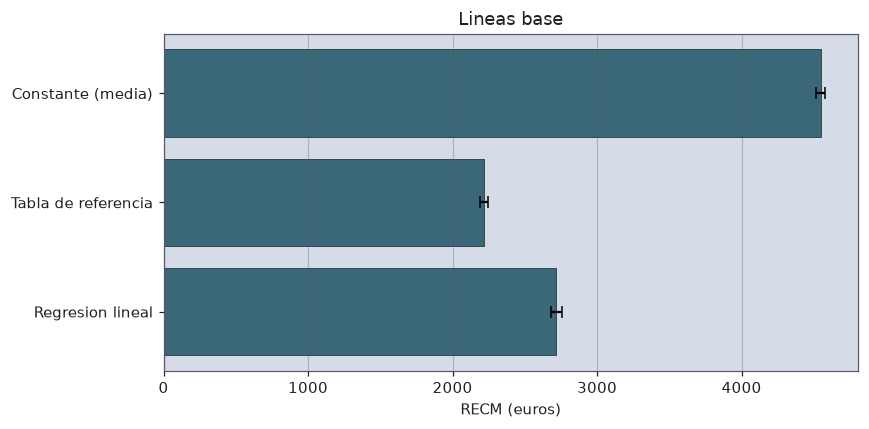

Umbral a superar por cualquier modelo del proyecto: 2218.66 euros


In [22]:
tabla_base = pd.DataFrame(resultados)
tabla_base["mejora_vs_constante_%"] = (
    (tabla_base.loc[0, "recm_media"] - tabla_base["recm_media"]) / tabla_base.loc[0, "recm_media"] * 100
).round(2)

display(
    tabla_base[[
        "modelo", "recm_media", "recm_desv", "mejora_vs_constante_%",
        "t_entrenamiento_s", "t_prediccion_lote_s", "latencia_individual_ms",
    ]].round(3)
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tabla_base["modelo"], tabla_base["recm_media"],
        xerr=tabla_base["recm_desv"], color=colores["base"],
        edgecolor=colores["neutro"], linewidth=0.5, capsize=4)
ax.set_xlabel("RECM (euros)")
ax.set_title("Lineas base")
ax.grid(True, axis="x")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

referencia = tabla_base.loc[tabla_base["modelo"] == "Tabla de referencia", "recm_media"].iloc[0]
print("Umbral a superar por cualquier modelo del proyecto:", f"{referencia:.2f}", "euros")

Las tres líneas base establecen el marco de referencia del proyecto.

La predicción constante fija el piso absoluto en 4 546.83 euros: es el error de no aprender
nada. La regresión lineal lo reduce en 40.22 %. La tabla de referencia lo reduce en 51.20 %,
superando al modelo lineal pese a su simplicidad.

**El umbral que debe superar cualquier modelo del proyecto es 2 218.66 euros.** Un método de
potenciación del gradiente que no lo supere carece de justificación frente a una consulta
sobre tres columnas que se ajusta en dieciocho milisegundos y ocupa 6 764 entradas.

La prueba de cordura queda establecida en 2 718.05 euros. Todo modelo basado en árboles que
arroje una RECM superior a esa cifra indica error de procedimiento, no limitación del método.

## 8. Modelos basados en árboles

### 8.1 Árbol de decisión

In [23]:
X_diag_train, X_diag_val, y_diag_train, y_diag_val = train_test_split(
    X_ohe_train, y_train, test_size=0.25, random_state=RANDOM_STATE
)

arbol_defecto = DecisionTreeRegressor(random_state=RANDOM_STATE)

inicio = time.perf_counter()
arbol_defecto.fit(X_diag_train, y_diag_train)
t_defecto = time.perf_counter() - inicio

recm_train_defecto = recm(y_diag_train, arbol_defecto.predict(X_diag_train))
recm_val_defecto = recm(y_diag_val, arbol_defecto.predict(X_diag_val))

print("Arbol con parametros por defecto")
print("  Profundidad alcanzada:", arbol_defecto.get_depth())
print("  Hojas:", f"{arbol_defecto.get_n_leaves():,}")
print("  Tiempo de ajuste:", f"{t_defecto:.2f}", "s")
print()
print("  RECM en entrenamiento:", f"{recm_train_defecto:.2f}", "euros")
print("  RECM en validacion:", f"{recm_val_defecto:.2f}", "euros")
print("  Brecha:", f"{recm_val_defecto - recm_train_defecto:.2f}", "euros")

Arbol con parametros por defecto
  Profundidad alcanzada: 91
  Hojas: 142,582
  Tiempo de ajuste: 2.04 s

  RECM en entrenamiento: 443.02 euros
  RECM en validacion: 2109.54 euros
  Brecha: 1666.52 euros


,max_depth,hojas,recm_train,recm_val,t_ajuste_s,brecha
0,4,16,2600.29,2630.73,0.54,30.45
1,6,64,2285.60,2319.20,0.74,33.60
2,8,253,2090.85,2153.40,0.92,62.56
3,10,913,1927.15,2050.18,1.12,123.03
4,12,2747,1750.08,1974.15,1.21,224.07
5,14,6552,1574.78,1946.88,1.35,372.11
6,16,12888,1401.14,1943.30,1.48,542.16
7,18,21845,1236.68,1960.36,1.51,723.69
8,20,32643,1088.11,1993.07,1.55,904.96
9,25,64005,780.66,2034.57,1.73,1253.91


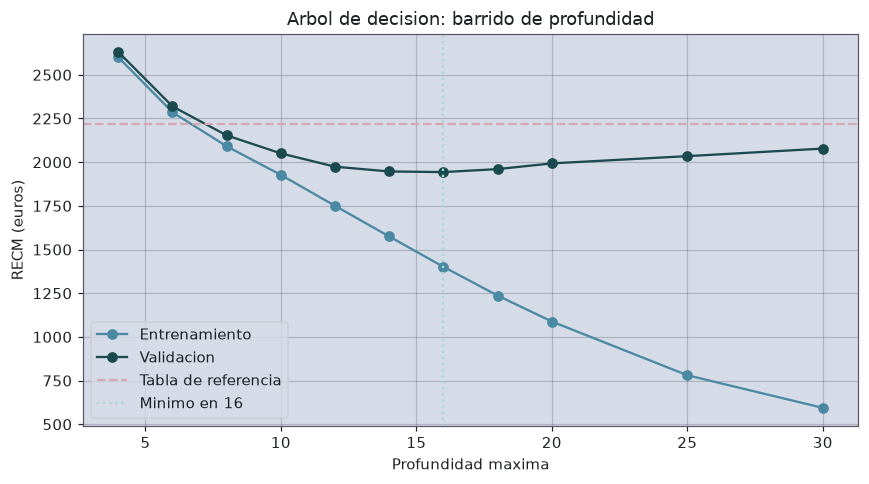

Profundidad con menor RECM de validacion: 16
RECM en ese punto: 1943.30 euros


In [24]:
profundidades = [4, 6, 8, 10, 12, 14, 16, 18, 20, 25, 30]
barrido_arbol = []

for prof in profundidades:
    modelo = DecisionTreeRegressor(max_depth=prof, random_state=RANDOM_STATE)
    inicio = time.perf_counter()
    modelo.fit(X_diag_train, y_diag_train)
    t = time.perf_counter() - inicio
    barrido_arbol.append({
        "max_depth": prof,
        "hojas": modelo.get_n_leaves(),
        "recm_train": recm(y_diag_train, modelo.predict(X_diag_train)),
        "recm_val": recm(y_diag_val, modelo.predict(X_diag_val)),
        "t_ajuste_s": t,
    })

barrido_arbol = pd.DataFrame(barrido_arbol)
barrido_arbol["brecha"] = barrido_arbol["recm_val"] - barrido_arbol["recm_train"]

display(barrido_arbol.round(2))

mejor_prof = int(barrido_arbol.loc[barrido_arbol["recm_val"].idxmin(), "max_depth"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(barrido_arbol["max_depth"], barrido_arbol["recm_train"],
        marker="o", color=colores["apoyo"], label="Entrenamiento")
ax.plot(barrido_arbol["max_depth"], barrido_arbol["recm_val"],
        marker="o", color=colores["arboles"], label="Validacion")
ax.axhline(referencia, color=colores["alerta"], linestyle="--", label="Tabla de referencia")
ax.axvline(mejor_prof, color=colores["ganador"], linestyle=":", label=f"Minimo en {mejor_prof}")
ax.set_xlabel("Profundidad maxima")
ax.set_ylabel("RECM (euros)")
ax.set_title("Arbol de decision: barrido de profundidad")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print("Profundidad con menor RECM de validacion:", mejor_prof)
print("RECM en ese punto:", f"{barrido_arbol['recm_val'].min():.2f}", "euros")

In [25]:
fila_14 = evaluar_modelo(
    "Arbol de decision (profundidad 14)",
    lambda: DecisionTreeRegressor(max_depth=14, random_state=RANDOM_STATE),
    X_ohe_train,
    y_train,
)
mostrar(fila_14)

print()

fila_16 = evaluar_modelo(
    "Arbol de decision (profundidad 16)",
    lambda: DecisionTreeRegressor(max_depth=16, random_state=RANDOM_STATE),
    X_ohe_train,
    y_train,
)
mostrar(fila_16)

print()
diferencia = fila_14["recm_media"] - fila_16["recm_media"]
print("Diferencia entre ambas profundidades:", f"{diferencia:.2f}", "euros")
print("Desviacion entre pliegues del mejor:", f"{min(fila_14['recm_desv'], fila_16['recm_desv']):.2f}", "euros")
print("Equivalentes segun la regla de la seccion 6.2:", abs(diferencia) < min(fila_14["recm_desv"], fila_16["recm_desv"]))

Arbol de decision (profundidad 14)
  RECM media: 1915.65 euros
  RECM desviacion entre pliegues: 12.53 euros
  RECM rango: 1901.09 a 1932.38
  Entrenamiento: 1.521 s
  Prediccion sobre 49,021 registros: 0.0173 s
  Latencia individual: 0.388 ms

Arbol de decision (profundidad 16)
  RECM media: 1910.67 euros
  RECM desviacion entre pliegues: 18.42 euros
  RECM rango: 1895.10 a 1941.56
  Entrenamiento: 1.601 s
  Prediccion sobre 49,021 registros: 0.0177 s
  Latencia individual: 0.385 ms

Diferencia entre ambas profundidades: 4.97 euros
Desviacion entre pliegues del mejor: 12.53 euros
Equivalentes segun la regla de la seccion 6.2: True


El diagnóstico previo emplea los parámetros por defecto sobre una partición interna del
conjunto de entrenamiento. Sin restricción de profundidad, el árbol alcanza 91 niveles y
142 582 hojas para 183 829 registros: 1.3 observaciones por hoja. La RECM resulta de 443.02
euros en entrenamiento frente a 2 109.54 en validación, con una brecha de 1 666.52 euros.

El diagnóstico es inequívoco: sobra capacidad. La dirección del ajuste es reducirla, y el
parámetro que la gobierna de forma más directa es la profundidad máxima. Se mueve un solo
parámetro y los restantes permanecen en su valor por defecto hasta disponer de evidencia que
justifique modificarlos.

El barrido sobre once profundidades produce el comportamiento característico: la RECM de
entrenamiento desciende de forma monótona desde 2 600.29 hasta 594.10 euros, mientras que la
de validación desciende, alcanza un mínimo de 1 943.30 euros en profundidad 16 y vuelve a
ascender.

El mínimo es plano. Entre profundidad 14 y 16 la mejora es de 3.58 euros, muy por debajo de
la escala de ruido de 30 euros establecida en la sección 7.1, mientras que la brecha crece de
372 a 542 euros y el número de hojas se duplica de 6 552 a 12 888.

La confirmación con validación cruzada arroja 1 915.65 euros para profundidad 14 y 1 910.67
para profundidad 16, con una diferencia de 4.97 euros frente a una desviación entre pliegues
de 12.53. La regla de decisión de la sección 6.2 los declara equivalentes, y la elección
recae en profundidad 14 por su menor complejidad.

El resultado supera la tabla de referencia en 303.01 euros, equivalentes a 13.66 %. Un árbol
único ya justifica su existencia frente al proceso actual.

### 8.2 Bosque aleatorio

In [26]:
combinaciones = [
    (30, 12), (30, 16), (30, 20),
    (60, 16), (60, 20), (60, 24),
    (100, 20),
]

barrido_bosque = []

for n_arboles, prof in combinaciones:
    modelo = RandomForestRegressor(
        n_estimators=n_arboles, max_depth=prof,
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    inicio = time.perf_counter()
    modelo.fit(X_diag_train, y_diag_train)
    t = time.perf_counter() - inicio
    barrido_bosque.append({
        "n_estimators": n_arboles,
        "max_depth": prof,
        "recm_train": recm(y_diag_train, modelo.predict(X_diag_train)),
        "recm_val": recm(y_diag_val, modelo.predict(X_diag_val)),
        "t_ajuste_s": t,
    })
    print(f"n_estimators={n_arboles}, max_depth={prof} -> RECM val {barrido_bosque[-1]['recm_val']:.2f}, {t:.1f} s")

barrido_bosque = pd.DataFrame(barrido_bosque)
barrido_bosque["brecha"] = barrido_bosque["recm_val"] - barrido_bosque["recm_train"]

print()
display(barrido_bosque.round(2))

n_estimators=30, max_depth=12 -> RECM val 1837.63, 5.7 s
n_estimators=30, max_depth=16 -> RECM val 1710.70, 7.0 s
n_estimators=30, max_depth=20 -> RECM val 1660.44, 6.9 s
n_estimators=60, max_depth=16 -> RECM val 1705.31, 12.6 s
n_estimators=60, max_depth=20 -> RECM val 1653.38, 14.0 s
n_estimators=60, max_depth=24 -> RECM val 1638.41, 14.9 s
n_estimators=100, max_depth=20 -> RECM val 1649.07, 25.3 s



,n_estimators,max_depth,recm_train,recm_val,t_ajuste_s,brecha
0,30,12,1652.06,1837.63,5.66,185.56
1,30,16,1323.67,1710.70,6.98,387.03
2,30,20,1072.50,1660.44,6.91,587.94
3,60,16,1317.51,1705.31,12.63,387.80
4,60,20,1063.12,1653.38,13.96,590.26
5,60,24,894.93,1638.41,14.91,743.48
6,100,20,1059.90,1649.07,25.27,589.17


In [27]:
barrido_extra = []

for prof in [28, 32, 36, None]:
    modelo = RandomForestRegressor(
        n_estimators=30, max_depth=prof,
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    inicio = time.perf_counter()
    modelo.fit(X_diag_train, y_diag_train)
    t = time.perf_counter() - inicio
    barrido_extra.append({
        "n_estimators": 30,
        "max_depth": prof if prof is not None else "sin limite",
        "recm_train": recm(y_diag_train, modelo.predict(X_diag_train)),
        "recm_val": recm(y_diag_val, modelo.predict(X_diag_val)),
        "t_ajuste_s": t,
    })
    print(f"max_depth={prof} -> RECM val {barrido_extra[-1]['recm_val']:.2f}, {t:.1f} s")

barrido_extra = pd.DataFrame(barrido_extra)
barrido_extra["brecha"] = barrido_extra["recm_val"] - barrido_extra["recm_train"]

print()
display(barrido_extra.round(2))

max_depth=28 -> RECM val 1644.84, 7.9 s
max_depth=32 -> RECM val 1646.40, 7.8 s
max_depth=36 -> RECM val 1650.43, 7.8 s
max_depth=None -> RECM val 1650.35, 8.0 s



,n_estimators,max_depth,recm_train,recm_val,t_ajuste_s,brecha
0,30,28,814.58,1644.84,7.94,830.26
1,30,32,768.50,1646.40,7.80,877.91
2,30,36,747.69,1650.43,7.80,902.75
3,30,sin limite,732.87,1650.35,7.99,917.48


In [28]:
fila = evaluar_modelo(
    "Bosque aleatorio (30 arboles, profundidad 24)",
    lambda: RandomForestRegressor(
        n_estimators=30, max_depth=24,
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
    X_ohe_train,
    y_train,
)

mostrar(fila)

print()
print("Mejora frente a la tabla de referencia:", f"{referencia - fila['recm_media']:.2f}", "euros")
print("Mejora frente al arbol de decision:", f"{fila_14['recm_media'] - fila['recm_media']:.2f}", "euros")
print("Costo de entrenamiento frente al arbol:", f"{fila['t_entrenamiento_s'] / fila_14['t_entrenamiento_s']:.1f}", "veces")

Bosque aleatorio (30 arboles, profundidad 24)
  RECM media: 1628.43 euros
  RECM desviacion entre pliegues: 18.22 euros
  RECM rango: 1607.83 a 1657.15
  Entrenamiento: 8.048 s
  Prediccion sobre 49,021 registros: 0.0649 s
  Latencia individual: 14.622 ms

Mejora frente a la tabla de referencia: 590.23 euros
Mejora frente al arbol de decision: 287.21 euros
Costo de entrenamiento frente al arbol: 5.3 veces


El bosque promedia árboles ajustados sobre muestras distintas del conjunto. El promedio
cancela la varianza de los árboles individuales, de modo que la memorización de cada uno deja
de traducirse en error del conjunto.

El primer barrido, sobre siete combinaciones de número de árboles y profundidad, arroja dos
hallazgos.

**La profundidad domina; el número de árboles apenas influye.** A profundidad 20, pasar de 30
a 100 árboles mejora la RECM de 1 660.44 a 1 649.07 euros, once euros que caen dentro del
ruido, mientras el tiempo de ajuste crece de 6.9 a 25.3 segundos. El trabajo escala de forma
lineal con el número de árboles, en tanto que el beneficio satura mucho antes que el costo.

**El óptimo de profundidad se desplaza hacia arriba.** El árbol único situaba su mínimo en 14;
el bosque continúa mejorando en 24. Es el efecto directo del promedio.

El segundo barrido localiza el fondo de la curva. El mínimo se alcanza en profundidad 28 con
1 644.84 euros, y a partir de ahí la curva es plana: 1 646.40 en profundidad 32, 1 650.43 en
36 y 1 650.35 sin límite alguno. Todo el rango entre 24 y sin restricción queda contenido en
doce euros.

El contraste con el árbol único es instructivo. Allí, omitir la poda costaba 166 euros de
RECM; aquí cuesta 5.5. La agregación cumple por sí sola la función reguladora.

La configuración elegida es de 30 árboles y profundidad 24: dentro del rango equivalente en
calidad, con el menor número de árboles, que es el parámetro que gobierna el costo.

Con validación cruzada el resultado es 1 628.43 euros, superior a la tabla de referencia en
590.23 euros y al árbol único en 287.21. El ajuste cuesta 5.3 veces más que el del árbol.

La latencia de predicción individual asciende a 14.622 milisegundos, frente a 0.388 del árbol:
casi cuarenta veces superior. Predecir un registro obliga a recorrer los treinta árboles, y la
paralelización no compensa el costo de reparto para una sola observación. Es el precio que la
aplicación paga por consulta de usuario, y se retoma en la sección 12.

## 9. Potenciación del gradiente

### 9.1 LightGBM

In [30]:
X_diag_train_cat = X_arboles_train.loc[X_diag_train.index]
X_diag_val_cat = X_arboles_train.loc[X_diag_val.index]

print("Verificacion de indices identicos a los usados en la seccion 8")
print("Entrenamiento:", X_diag_train_cat.index.equals(X_diag_train.index))
print("Validacion:", X_diag_val_cat.index.equals(X_diag_val.index))
print()

lgbm_defecto = lgb.LGBMRegressor(random_state=RANDOM_STATE, verbose=-1)

inicio = time.perf_counter()
lgbm_defecto.fit(X_diag_train_cat, y_diag_train)
t_lgbm_defecto = time.perf_counter() - inicio

recm_train_lgbm = recm(y_diag_train, lgbm_defecto.predict(X_diag_train_cat))
recm_val_lgbm = recm(y_diag_val, lgbm_defecto.predict(X_diag_val_cat))

print("LightGBM con parametros por defecto")
print("  n_estimators:", lgbm_defecto.n_estimators)
print("  learning_rate:", lgbm_defecto.learning_rate)
print("  num_leaves:", lgbm_defecto.num_leaves)
print("  Tiempo de ajuste:", f"{t_lgbm_defecto:.2f}", "s")
print()
print("  RECM en entrenamiento:", f"{recm_train_lgbm:.2f}", "euros")
print("  RECM en validacion:", f"{recm_val_lgbm:.2f}", "euros")
print("  Brecha:", f"{recm_val_lgbm - recm_train_lgbm:.2f}", "euros")
print()
print("  Columnas usadas:", X_diag_train_cat.shape[1])
print("  Categoricas nativas:", [c for c in X_diag_train_cat.columns if str(X_diag_train_cat[c].dtype) == "category"])

Verificacion de indices identicos a los usados en la seccion 8
Entrenamiento: True
Validacion: True

LightGBM con parametros por defecto
  n_estimators: 100
  learning_rate: 0.1
  num_leaves: 31
  Tiempo de ajuste: 0.60 s

  RECM en entrenamiento: 1568.55 euros
  RECM en validacion: 1660.48 euros
  Brecha: 91.93 euros

  Columnas usadas: 12
  Categoricas nativas: ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'Brand', 'NotRepaired']


In [31]:
configuraciones_lgbm = [
    {"n_estimators": 100, "learning_rate": 0.1, "num_leaves": 31},
    {"n_estimators": 300, "learning_rate": 0.1, "num_leaves": 31},
    {"n_estimators": 300, "learning_rate": 0.1, "num_leaves": 63},
    {"n_estimators": 300, "learning_rate": 0.1, "num_leaves": 127},
    {"n_estimators": 600, "learning_rate": 0.1, "num_leaves": 127},
    {"n_estimators": 600, "learning_rate": 0.05, "num_leaves": 127},
    {"n_estimators": 1200, "learning_rate": 0.05, "num_leaves": 127},
    {"n_estimators": 1200, "learning_rate": 0.05, "num_leaves": 255},
]

barrido_lgbm = []

for cfg in configuraciones_lgbm:
    modelo = lgb.LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1, **cfg)
    inicio = time.perf_counter()
    modelo.fit(X_diag_train_cat, y_diag_train)
    t = time.perf_counter() - inicio
    registro = dict(cfg)
    registro["recm_train"] = recm(y_diag_train, modelo.predict(X_diag_train_cat))
    registro["recm_val"] = recm(y_diag_val, modelo.predict(X_diag_val_cat))
    registro["t_ajuste_s"] = t
    registro["brecha"] = registro["recm_val"] - registro["recm_train"]
    barrido_lgbm.append(registro)
    print(f"N={cfg['n_estimators']:>4}  eta={cfg['learning_rate']:<5}  hojas={cfg['num_leaves']:>3}  ->  RECM val {registro['recm_val']:.2f}   brecha {registro['brecha']:.0f}   {t:.1f} s")

barrido_lgbm = pd.DataFrame(barrido_lgbm)

print()
display(barrido_lgbm.round(2))

N= 100  eta=0.1    hojas= 31  ->  RECM val 1660.48   brecha 92   0.6 s
N= 300  eta=0.1    hojas= 31  ->  RECM val 1600.55   brecha 147   1.6 s
N= 300  eta=0.1    hojas= 63  ->  RECM val 1572.07   brecha 211   2.8 s
N= 300  eta=0.1    hojas=127  ->  RECM val 1555.35   brecha 302   5.2 s
N= 600  eta=0.1    hojas=127  ->  RECM val 1549.96   brecha 399   10.2 s
N= 600  eta=0.05   hojas=127  ->  RECM val 1547.73   brecha 300   10.4 s
N=1200  eta=0.05   hojas=127  ->  RECM val 1539.96   brecha 397   20.1 s
N=1200  eta=0.05   hojas=255  ->  RECM val 1538.60   brecha 528   38.8 s



,n_estimators,learning_rate,num_leaves,recm_train,recm_val,t_ajuste_s,brecha
0,100,0.10,31,1568.55,1660.48,0.61,91.93
1,300,0.10,31,1453.54,1600.55,1.64,147.00
2,300,0.10,63,1360.59,1572.07,2.82,211.48
3,300,0.10,127,1253.19,1555.35,5.20,302.16
4,600,0.10,127,1150.53,1549.96,10.18,399.42
5,600,0.05,127,1248.13,1547.73,10.39,299.61
6,1200,0.05,127,1142.87,1539.96,20.11,397.08
7,1200,0.05,255,1010.59,1538.60,38.77,528.01


In [32]:
fila_lgbm = evaluar_modelo(
    "LightGBM (600 arboles, eta 0.05, 127 hojas)",
    lambda: lgb.LGBMRegressor(
        n_estimators=600, learning_rate=0.05, num_leaves=127,
        random_state=RANDOM_STATE, verbose=-1, n_jobs=-1,
    ),
    X_arboles_train,
    y_train,
)

mostrar(fila_lgbm)

print()
print("Mejora frente a la tabla de referencia:", f"{referencia - fila_lgbm['recm_media']:.2f}", "euros")
print("Mejora frente al bosque aleatorio:", f"{fila['recm_media'] - fila_lgbm['recm_media']:.2f}", "euros")
print("Columnas procesadas:", X_arboles_train.shape[1], "frente a", X_ohe_train.shape[1], "del bosque")

LightGBM (600 arboles, eta 0.05, 127 hojas)
  RECM media: 1527.02 euros
  RECM desviacion entre pliegues: 19.13 euros
  RECM rango: 1506.85 a 1552.53
  Entrenamiento: 10.975 s
  Prediccion sobre 49,021 registros: 0.2418 s
  Latencia individual: 0.659 ms

Mejora frente a la tabla de referencia: 691.64 euros
Mejora frente al bosque aleatorio: 101.41 euros
Columnas procesadas: 12 frente a 314 del bosque


El diagnóstico con parámetros por defecto —cien árboles, tasa de aprendizaje 0.1 y 31 hojas—
arroja 1 568.55 euros en entrenamiento contra 1 660.48 en validación, con una brecha de 91.93
euros y un tiempo de ajuste de 0.60 segundos.

El diagnóstico es opuesto al del árbol de decisión. Allí la brecha era de 1 666 euros y sobraba
capacidad; aquí es de 92 euros y falta. La dirección del ajuste es aumentarla.

Merece registro el punto de partida: en 0.60 segundos y sin ajuste alguno, LightGBM alcanza
1 660.48 euros, cifra que el bosque aleatorio obtuvo tras 6.9 segundos de entrenamiento.

El barrido explora ocho configuraciones en la dirección de mayor capacidad. La RECM desciende
de 1 660.48 a 1 538.60 euros, ciento veintidós euros de mejora, mientras el tiempo de ajuste
crece de 0.6 a 38.8 segundos, un factor de sesenta y cuatro. Los rendimientos decrecientes son
pronunciados.

El canje entre tasa de aprendizaje y número de árboles se observa con claridad en las
configuraciones cuarta y quinta. Con seiscientos árboles y ciento veintisiete hojas, reducir la
tasa de 0.1 a 0.05 deja la RECM prácticamente inalterada —1 549.96 frente a 1 547.73— pero
reduce la brecha de 399 a 300 euros, con idéntico tiempo de ajuste. La reducción de la tasa
regulariza sin costo.

Las últimas cuatro configuraciones quedan contenidas en once euros y son equivalentes bajo la
regla de la sección 6.2. La elección recae en seiscientos árboles, tasa 0.05 y ciento
veintisiete hojas: la de menor brecha dentro del grupo equivalente, a la cuarta parte del costo
de la más cara.

Con validación cruzada el resultado es 1 527.02 euros, el mejor del proyecto hasta este punto.
Supera a la tabla de referencia en 691.64 euros y al bosque aleatorio en 101.41, diferencia
que excede con holgura las desviaciones entre pliegues de ambos.

Dos magnitudes destacan. El entrenamiento cuesta 10.975 segundos frente a 8.048 del bosque,
apenas 1.36 veces más, procesando doce columnas en lugar de trescientas catorce. Y la latencia
de predicción individual es de 0.659 milisegundos frente a 14.622 del bosque, veintidós veces
menor: recorrer seiscientos árboles de ciento veintisiete hojas resulta más barato que recorrer
treinta árboles de profundidad veinticuatro.

### 9.2 XGBoost

In [33]:
configuraciones_xgb = [
    {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 6},
    {"n_estimators": 300, "learning_rate": 0.1, "max_depth": 7},
    {"n_estimators": 600, "learning_rate": 0.05, "max_depth": 7},
    {"n_estimators": 600, "learning_rate": 0.05, "max_depth": 9},
]

barrido_xgb = []

for cfg in configuraciones_xgb:
    modelo = xgb.XGBRegressor(
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist", **cfg
    )
    inicio = time.perf_counter()
    modelo.fit(X_diag_train, y_diag_train)
    t = time.perf_counter() - inicio
    registro = dict(cfg)
    registro["recm_train"] = recm(y_diag_train, modelo.predict(X_diag_train))
    registro["recm_val"] = recm(y_diag_val, modelo.predict(X_diag_val))
    registro["t_ajuste_s"] = t
    registro["brecha"] = registro["recm_val"] - registro["recm_train"]
    barrido_xgb.append(registro)
    print(f"N={cfg['n_estimators']:>4}  eta={cfg['learning_rate']:<5}  prof={cfg['max_depth']:>2}  ->  RECM val {registro['recm_val']:.2f}   brecha {registro['brecha']:.0f}   {t:.1f} s")

barrido_xgb = pd.DataFrame(barrido_xgb)

print()
display(barrido_xgb.round(2))

N= 100  eta=0.1    prof= 6  ->  RECM val 1743.28   brecha 77   1.2 s
N= 300  eta=0.1    prof= 7  ->  RECM val 1635.83   brecha 152   2.6 s
N= 600  eta=0.05   prof= 7  ->  RECM val 1635.88   brecha 146   4.9 s
N= 600  eta=0.05   prof= 9  ->  RECM val 1595.84   brecha 251   5.8 s



,n_estimators,learning_rate,max_depth,recm_train,recm_val,t_ajuste_s,brecha
0,100,0.10,6,1666.60,1743.28,1.24,76.68
1,300,0.10,7,1483.44,1635.83,2.62,152.39
2,600,0.05,7,1489.89,1635.88,4.91,145.99
3,600,0.05,9,1344.78,1595.84,5.77,251.06


In [34]:
barrido_xgb_extra = []

for prof in [11, 13]:
    modelo = xgb.XGBRegressor(
        n_estimators=600, learning_rate=0.05, max_depth=prof,
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
    )
    inicio = time.perf_counter()
    modelo.fit(X_diag_train, y_diag_train)
    t = time.perf_counter() - inicio
    registro = {"n_estimators": 600, "learning_rate": 0.05, "max_depth": prof}
    registro["recm_train"] = recm(y_diag_train, modelo.predict(X_diag_train))
    registro["recm_val"] = recm(y_diag_val, modelo.predict(X_diag_val))
    registro["t_ajuste_s"] = t
    registro["brecha"] = registro["recm_val"] - registro["recm_train"]
    barrido_xgb_extra.append(registro)
    print(f"prof={prof:>2}  ->  RECM val {registro['recm_val']:.2f}   brecha {registro['brecha']:.0f}   {t:.1f} s")

barrido_xgb_extra = pd.DataFrame(barrido_xgb_extra)

print()
display(barrido_xgb_extra.round(2))

prof=11  ->  RECM val 1573.86   brecha 398   7.4 s
prof=13  ->  RECM val 1572.70   brecha 559   9.1 s



,n_estimators,learning_rate,max_depth,recm_train,recm_val,t_ajuste_s,brecha
0,600,0.05,11,1175.50,1573.86,7.36,398.36
1,600,0.05,13,1013.89,1572.70,9.12,558.81


In [35]:
fila_xgb = evaluar_modelo(
    "XGBoost (600 arboles, eta 0.05, profundidad 11)",
    lambda: xgb.XGBRegressor(
        n_estimators=600, learning_rate=0.05, max_depth=11,
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
    ),
    X_ohe_train,
    y_train,
)

mostrar(fila_xgb)

print()
print("Diferencia frente a LightGBM:", f"{fila_xgb['recm_media'] - fila_lgbm['recm_media']:.2f}", "euros")
print("Razon de tiempo de entrenamiento frente a LightGBM:", f"{fila_xgb['t_entrenamiento_s'] / fila_lgbm['t_entrenamiento_s']:.2f}")
print("Columnas procesadas:", X_ohe_train.shape[1], "frente a", X_arboles_train.shape[1], "de LightGBM")

XGBoost (600 arboles, eta 0.05, profundidad 11)
  RECM media: 1556.75 euros
  RECM desviacion entre pliegues: 18.98 euros
  RECM rango: 1535.95 a 1579.85
  Entrenamiento: 7.203 s
  Prediccion sobre 49,021 registros: 0.0881 s
  Latencia individual: 5.376 ms

Diferencia frente a LightGBM: 29.73 euros
Razon de tiempo de entrenamiento frente a LightGBM: 0.66
Columnas procesadas: 314 frente a 12 de LightGBM


XGBoost constituye el contraste controlado del proyecto: mismo método de potenciación, distinta
representación de las variables categóricas. Opera sobre las trescientas catorce columnas
indicadoras, conforme indica el encargo.

Se emplea `max_depth` en lugar de `num_leaves` porque XGBoost desarrolla los árboles por nivel
y no por hoja. Un árbol de profundidad siete admite hasta ciento veintiocho hojas, magnitud
comparable a las ciento veintisiete empleadas en LightGBM.

El hallazgo del barrido es contraintuitivo: **XGBoost entrena más rápido que LightGBM pese a
procesar veintiséis veces más columnas.** Con seiscientos árboles y profundidad siete tarda 4.9
segundos, frente a 10.4 de LightGBM con seiscientos árboles y ciento veintisiete hojas.

La explicación reside en la estructura de los cortes candidatos. Una columna indicadora admite
un único punto de corte. Las trescientas ocho columnas binarias aportan, en conjunto,
trescientos ocho cortes candidatos. LightGBM, en cambio, evalúa sobre `Model` con doscientas
cincuenta categorías un número de particiones muy superior. La expansión de columnas encarece la
memoria pero abarata la búsqueda por columna.

La curva alcanza meseta en profundidad once, con 1 573.86 euros, frente a 1 572.70 en
profundidad trece. La diferencia de 1.16 euros no justifica el crecimiento de la brecha de 398
a 559.

Con validación cruzada el resultado es 1 556.75 euros, 29.73 por encima de LightGBM. La
diferencia excede la desviación entre pliegues de 19 euros, de modo que es real, si bien
modesta.

En tiempos, la relación se invierte según la magnitud considerada. XGBoost entrena en 7.203
segundos frente a 10.975 de LightGBM, con una razón de 0.66. Pero su latencia individual es de
5.376 milisegundos frente a 0.659, ocho veces superior. La causa es estructural: el crecimiento
por nivel desarrolla todas las ramas por igual, de modo que un árbol de profundidad once
contiene hasta dos mil cuarenta y ocho hojas y sus recorridos son uniformemente largos. El
crecimiento por hoja de LightGBM expande únicamente donde existe ganancia, y produce recorridos
más cortos.

### 9.3 CatBoost

In [36]:
columnas_cat_catboost = [c for c in X_arboles_train.columns if str(X_arboles_train[c].dtype) == "category"]

X_diag_train_cb = X_diag_train_cat.copy()
X_diag_val_cb = X_diag_val_cat.copy()
for c in columnas_cat_catboost:
    X_diag_train_cb[c] = X_diag_train_cb[c].astype(str)
    X_diag_val_cb[c] = X_diag_val_cb[c].astype(str)

configuraciones_cb = [
    {"iterations": 300, "learning_rate": 0.1, "depth": 6},
    {"iterations": 600, "learning_rate": 0.05, "depth": 8},
    {"iterations": 1000, "learning_rate": 0.05, "depth": 10},
]

barrido_cb = []

for cfg in configuraciones_cb:
    modelo = CatBoostRegressor(
        random_state=RANDOM_STATE, verbose=0,
        cat_features=columnas_cat_catboost, **cfg
    )
    inicio = time.perf_counter()
    modelo.fit(X_diag_train_cb, y_diag_train)
    t = time.perf_counter() - inicio
    registro = dict(cfg)
    registro["recm_train"] = recm(y_diag_train, modelo.predict(X_diag_train_cb))
    registro["recm_val"] = recm(y_diag_val, modelo.predict(X_diag_val_cb))
    registro["t_ajuste_s"] = t
    registro["brecha"] = registro["recm_val"] - registro["recm_train"]
    barrido_cb.append(registro)
    print(f"N={cfg['iterations']:>4}  eta={cfg['learning_rate']:<5}  prof={cfg['depth']:>2}  ->  RECM val {registro['recm_val']:.2f}   brecha {registro['brecha']:.0f}   {t:.1f} s")

barrido_cb = pd.DataFrame(barrido_cb)

print()
display(barrido_cb.round(2))

N= 300  eta=0.1    prof= 6  ->  RECM val 1694.44   brecha 61   6.4 s
N= 600  eta=0.05   prof= 8  ->  RECM val 1644.85   brecha 94   15.8 s
N=1000  eta=0.05   prof=10  ->  RECM val 1590.59   brecha 185   38.9 s



,iterations,learning_rate,depth,recm_train,recm_val,t_ajuste_s,brecha
0,300,0.10,6,1633.24,1694.44,6.41,61.20
1,600,0.05,8,1550.90,1644.85,15.77,93.95
2,1000,0.05,10,1405.72,1590.59,38.87,184.86


In [37]:
barrido_cb_extra = []

for cfg in [{"iterations": 1500, "learning_rate": 0.05, "depth": 12}]:
    modelo = CatBoostRegressor(
        random_state=RANDOM_STATE, verbose=0,
        cat_features=columnas_cat_catboost, **cfg
    )
    inicio = time.perf_counter()
    modelo.fit(X_diag_train_cb, y_diag_train)
    t = time.perf_counter() - inicio
    registro = dict(cfg)
    registro["recm_train"] = recm(y_diag_train, modelo.predict(X_diag_train_cb))
    registro["recm_val"] = recm(y_diag_val, modelo.predict(X_diag_val_cb))
    registro["t_ajuste_s"] = t
    registro["brecha"] = registro["recm_val"] - registro["recm_train"]
    barrido_cb_extra.append(registro)
    print(f"N={cfg['iterations']}  eta={cfg['learning_rate']}  prof={cfg['depth']}  ->  RECM val {registro['recm_val']:.2f}   brecha {registro['brecha']:.0f}   {t:.1f} s")

barrido_cb_extra = pd.DataFrame(barrido_cb_extra)

print()
display(barrido_cb_extra.round(2))

N=1500  eta=0.05  prof=12  ->  RECM val 1562.76   brecha 334   85.8 s



,iterations,learning_rate,depth,recm_train,recm_val,t_ajuste_s,brecha
0,1500,0.05,12,1229.13,1562.76,85.82,333.62


In [38]:
X_catboost_train = X_arboles_train.copy()
for c in columnas_cat_catboost:
    X_catboost_train[c] = X_catboost_train[c].astype(str)

fila_cb = evaluar_modelo(
    "CatBoost (1000 iteraciones, eta 0.05, profundidad 10)",
    lambda: CatBoostRegressor(
        iterations=1000, learning_rate=0.05, depth=10,
        random_state=RANDOM_STATE, verbose=0,
        cat_features=columnas_cat_catboost,
    ),
    X_catboost_train,
    y_train,
)

mostrar(fila_cb)

print()
print("Diferencia frente a LightGBM:", f"{fila_cb['recm_media'] - fila_lgbm['recm_media']:.2f}", "euros")
print("Razon de tiempo de entrenamiento frente a LightGBM:", f"{fila_cb['t_entrenamiento_s'] / fila_lgbm['t_entrenamiento_s']:.2f}")

CatBoost (1000 iteraciones, eta 0.05, profundidad 10)
  RECM media: 1567.63 euros
  RECM desviacion entre pliegues: 20.40 euros
  RECM rango: 1548.52 a 1598.48
  Entrenamiento: 41.538 s
  Prediccion sobre 49,021 registros: 0.0547 s
  Latencia individual: 0.221 ms

Diferencia frente a LightGBM: 40.61 euros
Razon de tiempo de entrenamiento frente a LightGBM: 3.78


CatBoost procesa las categóricas mediante estadísticas ordenadas, mecanismo que impide que la
codificación por objetivo filtre información del propio registro. Sus árboles son simétricos:
todos los nodos de un mismo nivel comparten el corte.

El barrido revela la firma característica del método: **las brechas más pequeñas del proyecto.**
Sesenta y uno, noventa y cuatro y ciento ochenta y cinco euros, frente a trescientos,
trescientos noventa y nueve y quinientos veintiocho de LightGBM en configuraciones análogas. Las
estadísticas ordenadas y la simetría de los árboles regularizan de forma agresiva.

La ventaja se pierde al forzar la capacidad. Con mil quinientas iteraciones y profundidad doce
la brecha salta a 334 euros y el ajuste consume 85.82 segundos para alcanzar 1 562.76 euros,
cifra que LightGBM supera en 10.4 segundos.

La configuración elegida es de mil iteraciones, tasa 0.05 y profundidad diez. La alternativa de
mil quinientas mejora veintiocho euros a cambio de cuarenta y siete segundos adicionales,
proporción inadmisible en un encargo cuyo objeto es precisamente esa relación.

Con validación cruzada el resultado es 1 567.63 euros, 40.61 por encima de LightGBM. En calidad
ocupa el tercer lugar entre los métodos de potenciación.

La inversión de posiciones entre las dos magnitudes de tiempo constituye el hallazgo central de
esta sección. CatBoost es el más lento de entrenar, con 41.538 segundos y una razón de 3.78
frente a LightGBM, y a la vez **el más rápido de predecir de todo el proyecto**, con 0.221
milisegundos de latencia individual, tres veces por debajo de LightGBM. La simetría de los
árboles reduce el recorrido a una operación aritmética sobre índices, en lugar de una secuencia
de comparaciones condicionales.

## 10. Análisis de velocidad

### 10.1 Tiempo de entrenamiento

,etiqueta,recm_media,recm_desv,t_entrenamiento_s
0,Constante,4546.825,29.941,0.000
1,Tabla ref.,2218.664,29.550,0.018
2,Reg. lineal,2718.051,37.349,1.226
3,Arbol,1915.648,12.529,1.521
4,Bosque,1628.434,18.219,8.048
5,LightGBM,1527.021,19.129,10.975
6,XGBoost,1556.746,18.982,7.203
7,CatBoost,1567.630,20.400,41.538


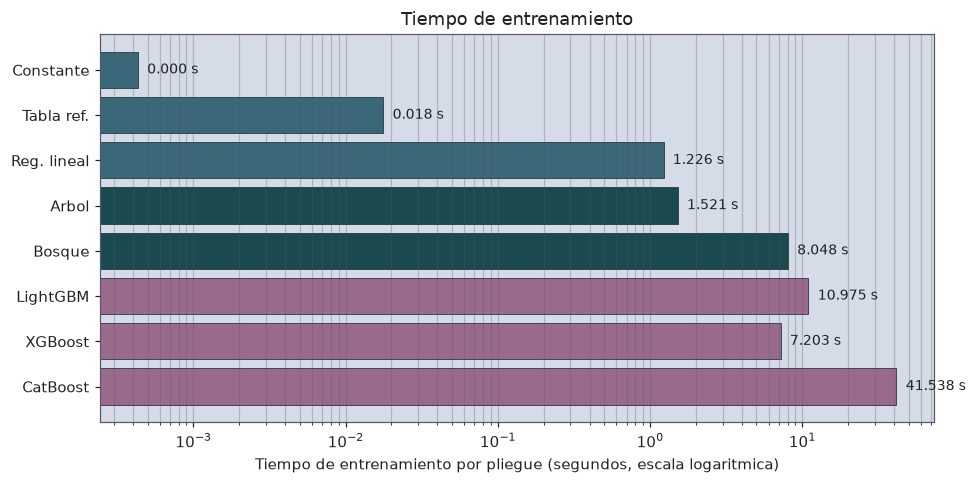

Modelo mas rapido de entrenar: Constante
Modelo mas lento de entrenar: CatBoost
Razon entre ambos: 96,161 veces


In [39]:
tabla_resultados = pd.DataFrame(resultados)
tabla_resultados = tabla_resultados[
    tabla_resultados["modelo"] != "Arbol de decision (profundidad 16)"
].reset_index(drop=True)

etiquetas = {
    "Constante (media)": "Constante",
    "Tabla de referencia": "Tabla ref.",
    "Regresion lineal": "Reg. lineal",
    "Arbol de decision (profundidad 14)": "Arbol",
    "Bosque aleatorio (30 arboles, profundidad 24)": "Bosque",
    "LightGBM (600 arboles, eta 0.05, 127 hojas)": "LightGBM",
    "XGBoost (600 arboles, eta 0.05, profundidad 11)": "XGBoost",
    "CatBoost (1000 iteraciones, eta 0.05, profundidad 10)": "CatBoost",
}
tabla_resultados["etiqueta"] = tabla_resultados["modelo"].map(etiquetas)

familia = {
    "Constante": colores["base"], "Tabla ref.": colores["base"], "Reg. lineal": colores["base"],
    "Arbol": colores["arboles"], "Bosque": colores["arboles"],
    "LightGBM": colores["potenciacion"], "XGBoost": colores["potenciacion"], "CatBoost": colores["potenciacion"],
}
tabla_resultados["color"] = tabla_resultados["etiqueta"].map(familia)

display(tabla_resultados[["etiqueta", "recm_media", "recm_desv", "t_entrenamiento_s"]].round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(tabla_resultados["etiqueta"], tabla_resultados["t_entrenamiento_s"],
        color=tabla_resultados["color"], edgecolor=colores["neutro"], linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("Tiempo de entrenamiento por pliegue (segundos, escala logaritmica)")
ax.set_title("Tiempo de entrenamiento")
ax.grid(True, axis="x", which="both")
ax.invert_yaxis()
for i, v in enumerate(tabla_resultados["t_entrenamiento_s"]):
    ax.text(v * 1.15, i, f"{v:.3f} s", va="center", fontsize=9)
plt.tight_layout()
plt.show()

print("Modelo mas rapido de entrenar:", tabla_resultados.loc[tabla_resultados["t_entrenamiento_s"].idxmin(), "etiqueta"])
print("Modelo mas lento de entrenar:", tabla_resultados.loc[tabla_resultados["t_entrenamiento_s"].idxmax(), "etiqueta"])
print("Razon entre ambos:", f"{tabla_resultados['t_entrenamiento_s'].max() / max(tabla_resultados['t_entrenamiento_s'].min(), 1e-6):,.0f}", "veces")

Las mediciones corresponden a la mediana sobre los cinco pliegues, con reloj monótono de alta
resolución. Se excluye el árbol de profundidad dieciséis, evaluado únicamente para verificar la
equivalencia con profundidad catorce.

El rango abarca cinco órdenes de magnitud, de milésimas de segundo a 41.5 segundos, motivo por
el cual la representación emplea escala logarítmica.

Entre los cinco modelos que superan la tabla de referencia, el más rápido de entrenar es el
árbol de decisión con 1.521 segundos y el más lento CatBoost con 41.538, razón de 27.3 veces.
Entre los tres métodos de potenciación, el rango va de 7.203 segundos de XGBoost a 41.538 de
CatBoost, razón de 5.8.

La comparación entre el bosque aleatorio y LightGBM merece atención. El bosque emplea 8.048
segundos sobre trescientas catorce columnas; LightGBM emplea 10.975 sobre doce. La razón de
1.36 en tiempo contra una razón de 0.04 en columnas indica que el costo no está gobernado por el
número de columnas, sino por la cantidad de árboles ajustados y por el número de cortes
evaluados en cada uno.

### 10.2 Tiempo de predicción por lote

,etiqueta,t_prediccion_lote_s,registros_lote,registros_por_segundo
0,Constante,0.0001,49021,530915562.0
1,Tabla ref.,0.0089,49021,5530893.0
2,Reg. lineal,0.0222,49021,2204186.0
3,Arbol,0.0173,49021,2833823.0
4,Bosque,0.0649,49021,755056.0
5,LightGBM,0.2418,49021,202742.0
6,XGBoost,0.0881,49021,556565.0
7,CatBoost,0.0547,49021,895926.0


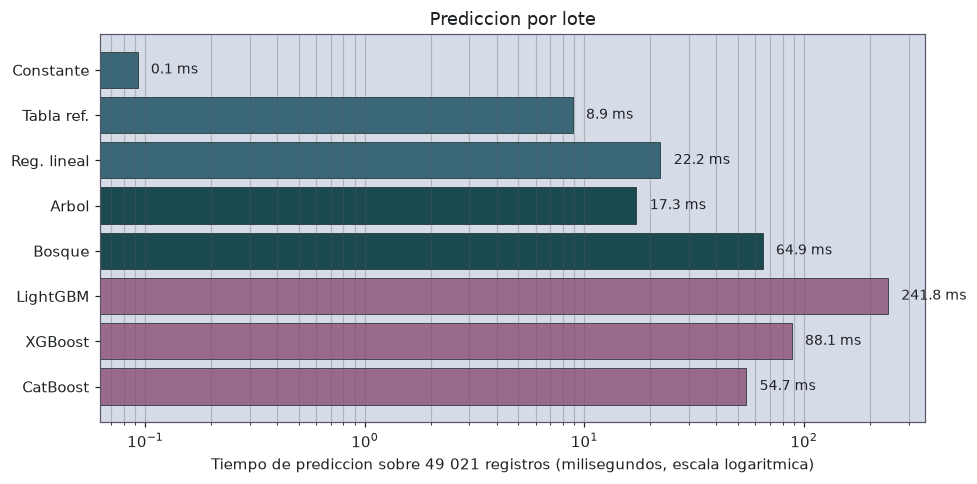

Modelos que superan la tabla de referencia: 5
Mayor rendimiento por lote: Arbol
Menor rendimiento por lote: LightGBM


In [40]:
tabla_resultados["registros_por_segundo"] = (
    tabla_resultados["registros_lote"] / tabla_resultados["t_prediccion_lote_s"]
)

display(
    tabla_resultados[["etiqueta", "t_prediccion_lote_s", "registros_lote", "registros_por_segundo"]]
    .assign(registros_por_segundo=lambda d: d["registros_por_segundo"].round(0))
    .round(4)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(tabla_resultados["etiqueta"], tabla_resultados["t_prediccion_lote_s"] * 1000,
        color=tabla_resultados["color"], edgecolor=colores["neutro"], linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("Tiempo de prediccion sobre 49 021 registros (milisegundos, escala logaritmica)")
ax.set_title("Prediccion por lote")
ax.grid(True, axis="x", which="both")
ax.invert_yaxis()
for i, v in enumerate(tabla_resultados["t_prediccion_lote_s"] * 1000):
    ax.text(v * 1.15, i, f"{v:.1f} ms", va="center", fontsize=9)
plt.tight_layout()
plt.show()

con_capacidad = tabla_resultados[tabla_resultados["recm_media"] < referencia]
print("Modelos que superan la tabla de referencia:", len(con_capacidad))
print("Mayor rendimiento por lote:", con_capacidad.loc[con_capacidad["registros_por_segundo"].idxmax(), "etiqueta"])
print("Menor rendimiento por lote:", con_capacidad.loc[con_capacidad["registros_por_segundo"].idxmin(), "etiqueta"])

El tiempo de lote se normaliza a registros procesados por segundo, magnitud transferible a
volúmenes distintos del pliegue de 49 021 registros empleado. Corresponde al escenario de valuar
un inventario completo o reprocesar el catálogo.

El resultado invierte el orden establecido en la sección anterior. **LightGBM resulta el más
lento por lote de todos los modelos evaluados**, con 241.8 milisegundos y 202 742 registros por
segundo, pese a ser el segundo más rápido en latencia individual. CatBoost, el más lento de
entrenar, procesa el lote en 54.7 milisegundos y alcanza 895 926 registros por segundo.

Entre los tres métodos de potenciación el orden por lote es CatBoost, XGBoost y LightGBM,
exactamente inverso al orden por latencia individual, que es CatBoost, LightGBM y XGBoost. Solo
CatBoost encabeza ambas magnitudes.

El desempeño de LightGBM se explica por la estructura del modelo: seiscientos árboles obligan a
seiscientos recorridos por registro, que sobre 49 021 registros suman veintinueve millones de
recorridos. XGBoost dispone del mismo número de árboles pero aprovecha la vectorización sobre
columnas indicadoras cuando opera en lote, ventaja que desaparece con una observación aislada.

### 10.3 Latencia de predicción individual

,etiqueta,us_por_registro_en_lote,us_individual,sobrecosto_individual
0,Constante,0.0,4.5,2389.2
1,Tabla ref.,0.2,925.1,5116.4
2,Reg. lineal,0.5,361.4,796.6
3,Arbol,0.4,387.8,1099.0
4,Bosque,1.3,14621.6,11040.1
5,LightGBM,4.9,658.7,133.5
6,XGBoost,1.8,5375.5,2991.8
7,CatBoost,1.1,221.1,198.1


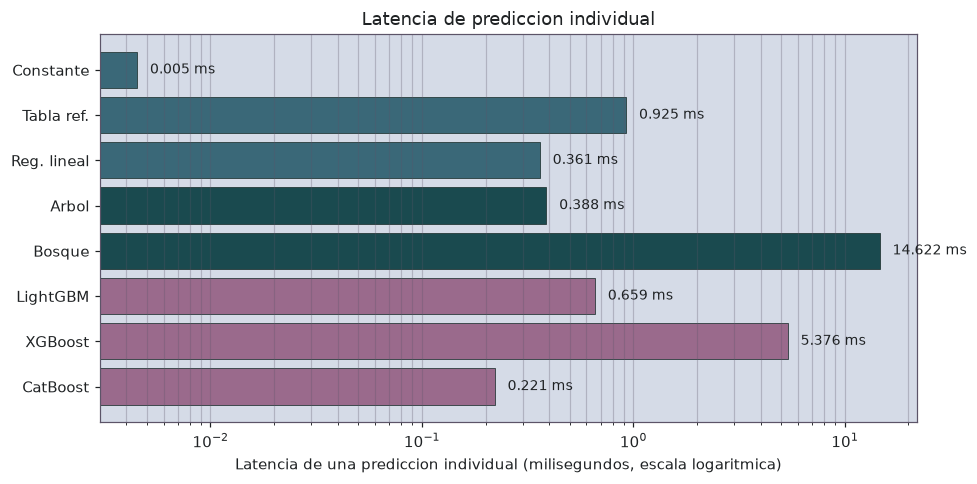

Menor latencia entre modelos que superan la tabla de referencia:
  CatBoost 0.221 ms
Mayor latencia:
  Bosque 14.622 ms


In [41]:
tabla_resultados["us_por_registro_en_lote"] = (
    tabla_resultados["t_prediccion_lote_s"] / tabla_resultados["registros_lote"] * 1e6
)
tabla_resultados["us_individual"] = tabla_resultados["latencia_individual_ms"] * 1000
tabla_resultados["sobrecosto_individual"] = (
    tabla_resultados["us_individual"] / tabla_resultados["us_por_registro_en_lote"]
)

display(
    tabla_resultados[[
        "etiqueta", "us_por_registro_en_lote", "us_individual", "sobrecosto_individual",
    ]].round(1)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(tabla_resultados["etiqueta"], tabla_resultados["latencia_individual_ms"],
        color=tabla_resultados["color"], edgecolor=colores["neutro"], linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("Latencia de una prediccion individual (milisegundos, escala logaritmica)")
ax.set_title("Latencia de prediccion individual")
ax.grid(True, axis="x", which="both")
ax.invert_yaxis()
for i, v in enumerate(tabla_resultados["latencia_individual_ms"]):
    ax.text(v * 1.15, i, f"{v:.3f} ms", va="center", fontsize=9)
plt.tight_layout()
plt.show()

print("Menor latencia entre modelos que superan la tabla de referencia:")
print(" ", con_capacidad.loc[con_capacidad["latencia_individual_ms"].idxmin(), "etiqueta"],
      f"{con_capacidad['latencia_individual_ms'].min():.3f} ms")
print("Mayor latencia:")
print(" ", con_capacidad.loc[con_capacidad["latencia_individual_ms"].idxmax(), "etiqueta"],
      f"{con_capacidad['latencia_individual_ms'].max():.3f} ms")

La latencia individual corresponde al caso de uso real del encargo: un usuario, una consulta, un
precio. Se mide prediciendo un registro aislado y repitiendo cien veces, con reporte de la
mediana.

No equivale a dividir el tiempo de lote entre el número de registros. La comparación entre ambas
magnitudes cuantifica el gasto fijo por llamada, que comprende la validación de la entrada, la
conversión a la estructura interna del modelo y, en su caso, el reparto entre núcleos.

El sobrecosto de la predicción aislada frente al costo por registro dentro del lote va de 133.5
a 11 040.1 veces según el modelo, y explica por qué los dos órdenes no coinciden.

LightGBM presenta el sobrecosto menor, de 133.5, y CatBoost el segundo, de 198.1. El bosque
aleatorio alcanza 11 040.1: la distribución de treinta árboles entre núcleos resulta más costosa
que el propio cálculo cuando la entrada es una sola fila. XGBoost registra 2 991.8, atribuible
a la construcción de la estructura interna para una fila de trescientas catorce columnas.

Entre los modelos que superan la tabla de referencia, la latencia menor corresponde a CatBoost
con 0.221 milisegundos y la mayor al bosque aleatorio con 14.622, razón de sesenta y seis veces.

## 11. Escalamiento empírico

### 11.1 Diseño de la medición

In [42]:
fracciones = [0.10, 0.25, 0.50, 0.75, 1.00]

modelos_escalamiento = [
    ("Arbol", lambda: DecisionTreeRegressor(max_depth=14, random_state=RANDOM_STATE), X_ohe_train),
    ("Bosque", lambda: RandomForestRegressor(n_estimators=30, max_depth=24, random_state=RANDOM_STATE, n_jobs=-1), X_ohe_train),
    ("LightGBM", lambda: lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=127, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1), X_arboles_train),
    ("XGBoost", lambda: xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=11, random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist"), X_ohe_train),
    ("CatBoost", lambda: CatBoostRegressor(iterations=1000, learning_rate=0.05, depth=10, random_state=RANDOM_STATE, verbose=0, cat_features=columnas_cat_catboost), X_catboost_train),
]

escalamiento = []

for nombre, constructor, X_fuente in modelos_escalamiento:
    for fraccion in fracciones:
        n = int(len(X_fuente) * fraccion)
        idx = X_fuente.sample(n=n, random_state=RANDOM_STATE).index
        X_sub = X_fuente.loc[idx]
        y_sub = y_train.loc[idx]

        modelo = constructor()
        inicio = time.perf_counter()
        modelo.fit(X_sub, y_sub)
        t = time.perf_counter() - inicio

        escalamiento.append({"modelo": nombre, "fraccion": fraccion, "n": n, "t_ajuste_s": t})
        print(f"{nombre:<9}  n={n:>7,}  ->  {t:>7.3f} s")
    print()

escalamiento = pd.DataFrame(escalamiento)
display(escalamiento.round(3))

Arbol      n= 24,510  ->    0.129 s
Arbol      n= 61,276  ->    0.372 s
Arbol      n=122,553  ->    0.910 s
Arbol      n=183,829  ->    1.437 s
Arbol      n=245,106  ->    1.896 s

Bosque     n= 24,510  ->    0.540 s
Bosque     n= 61,276  ->    1.982 s
Bosque     n=122,553  ->    4.555 s
Bosque     n=183,829  ->    7.459 s
Bosque     n=245,106  ->   10.887 s

LightGBM   n= 24,510  ->    9.384 s
LightGBM   n= 61,276  ->    9.626 s
LightGBM   n=122,553  ->   10.085 s
LightGBM   n=183,829  ->   10.244 s
LightGBM   n=245,106  ->   10.868 s

XGBoost    n= 24,510  ->    2.338 s
XGBoost    n= 61,276  ->    3.357 s
XGBoost    n=122,553  ->    5.140 s
XGBoost    n=183,829  ->    7.048 s
XGBoost    n=245,106  ->    9.184 s

CatBoost   n= 24,510  ->    8.525 s
CatBoost   n= 61,276  ->   15.883 s
CatBoost   n=122,553  ->   27.753 s
CatBoost   n=183,829  ->   38.830 s
CatBoost   n=245,106  ->   52.453 s



,modelo,fraccion,n,t_ajuste_s
0,Arbol,0.10,24510,0.129
1,Arbol,0.25,61276,0.372
2,Arbol,0.50,122553,0.910
3,Arbol,0.75,183829,1.437
4,Arbol,1.00,245106,1.896
5,Bosque,0.10,24510,0.540
6,Bosque,0.25,61276,1.982
7,Bosque,0.50,122553,4.555
8,Bosque,0.75,183829,7.459
9,Bosque,1.00,245106,10.887


La medición determina cómo escala el tiempo de entrenamiento con el número de registros. Se
postula la relación de potencia

    T(n) = c · n^k

donde T(n) es el tiempo de ajuste, n el número de registros, c una constante de proporcionalidad
y k el exponente que se busca estimar.

El diseño emplea cinco tamaños —diez, veinticinco, cincuenta, setenta y cinco y cien por ciento
del conjunto de entrenamiento— obtenidos por muestreo con semilla fija, de modo que cada
submuestra constituya un subconjunto y no una población distinta. Cada modelo se ajusta una vez
por tamaño con la configuración seleccionada en las secciones 8 y 9, sobre su propia
representación de las variables categóricas.

Las cifras no coinciden con las de la sección 10. Allí se reportó la mediana sobre cinco pliegues
de 196 084 registros; aquí se trata de un ajuste único sobre hasta 245 106.

Un resultado se aprecia antes de cualquier cálculo. LightGBM pasa de 9.384 a 10.868 segundos
mientras el número de registros se multiplica por diez: un incremento de 16 % en tiempo ante uno
de 900 % en datos. CatBoost presenta el comportamiento opuesto, de 8.5 a 52.5 segundos.

### 11.2 Curva de tiempo frente al número de registros

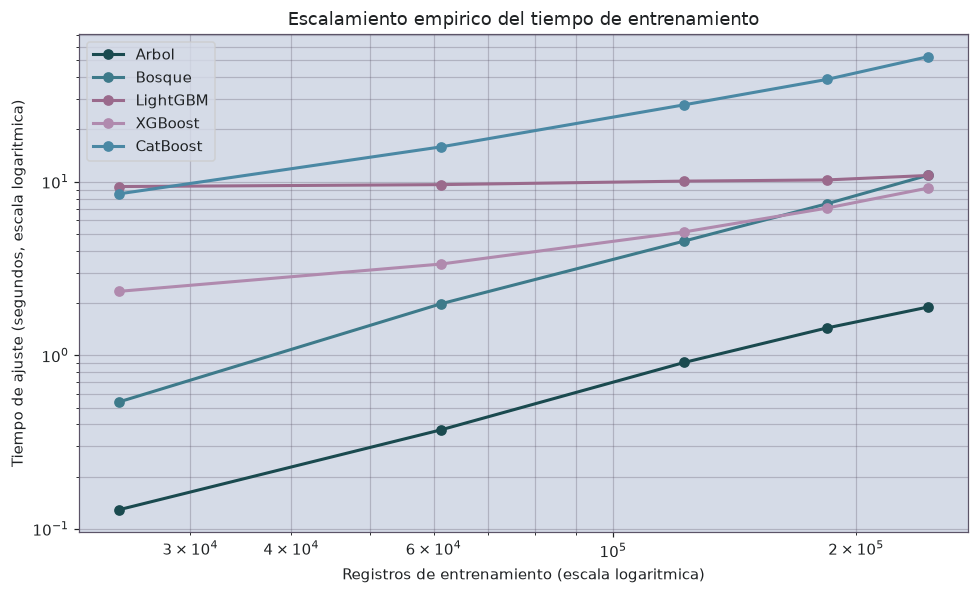

En escala logaritmica doble, la pendiente de cada recta es el exponente k de T(n) ~ n^k


In [43]:
fig, ax = plt.subplots(figsize=(9, 5.5))

colores_modelo = {
    "Arbol": colores["arboles"],
    "Bosque": colores["teal"],
    "LightGBM": colores["potenciacion"],
    "XGBoost": colores["malva"],
    "CatBoost": colores["apoyo"],
}

for nombre in escalamiento["modelo"].unique():
    sub = escalamiento[escalamiento["modelo"] == nombre]
    ax.plot(sub["n"], sub["t_ajuste_s"], marker="o",
            color=colores_modelo[nombre], label=nombre, linewidth=2)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Registros de entrenamiento (escala logaritmica)")
ax.set_ylabel("Tiempo de ajuste (segundos, escala logaritmica)")
ax.set_title("Escalamiento empirico del tiempo de entrenamiento")
ax.legend()
ax.grid(True, which="both")
plt.tight_layout()
plt.show()

print("En escala logaritmica doble, la pendiente de cada recta es el exponente k de T(n) ~ n^k")

La representación emplea escala logarítmica en ambos ejes. Bajo la relación de potencia, tomar
logaritmos produce

    log T = log c + k · log n

que es la ecuación de una recta cuya pendiente es el exponente k y cuya ordenada al origen es
log c. La linealidad de las cinco trayectorias confirma que la relación de potencia describe
adecuadamente el comportamiento observado.

Las pendientes difieren de forma manifiesta: LightGBM se aproxima a la horizontal, mientras que
el árbol y el bosque presentan las mayores inclinaciones.

La gráfica revela un cruce que la tabla no permitía advertir. Las trayectorias del bosque
aleatorio y de LightGBM se intersecan en las proximidades de 245 000 registros. Por debajo de ese
punto el bosque resulta más económico; por encima, LightGBM. La cuantificación de esa divergencia
corresponde a la extrapolación de la subsección siguiente.

### 11.3 Exponente estimado

,modelo,exponente_k,constante_c,r2,t_observado_245106_s,t_extrapolado_10M_s,t_extrapolado_10M_min
2,LightGBM,0.0583,5.1378,0.8925,10.8676,13.1440,0.2191
3,XGBoost,0.5887,0.0056,0.9747,9.1842,74.2055,1.2368
4,CatBoost,0.7822,0.0030,0.9955,52.4534,899.1776,14.9863
0,Arbol,1.1841,0.0000,0.9990,1.8959,159.5215,2.6587
1,Bosque,1.2923,0.0000,0.9986,10.8874,1333.9783,22.2330


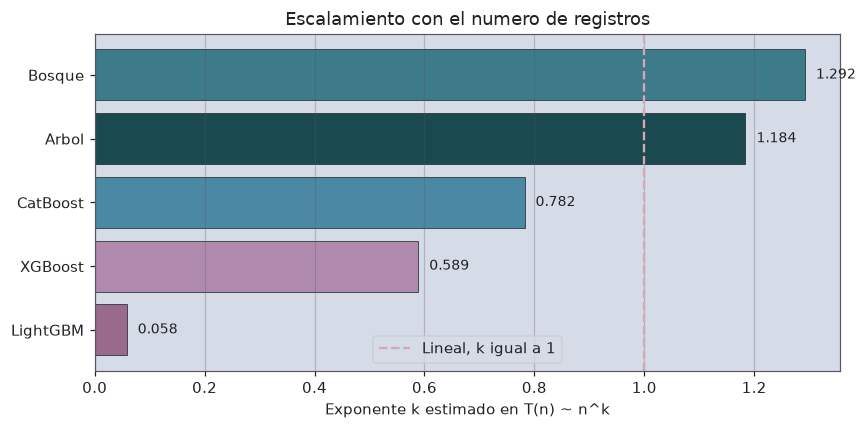

In [44]:
exponentes = []

for nombre in escalamiento["modelo"].unique():
    sub = escalamiento[escalamiento["modelo"] == nombre]
    log_n = np.log(sub["n"].to_numpy())
    log_t = np.log(sub["t_ajuste_s"].to_numpy())

    k, log_c = np.polyfit(log_n, log_t, 1)

    log_t_ajustado = k * log_n + log_c
    ss_res = float(np.sum((log_t - log_t_ajustado) ** 2))
    ss_tot = float(np.sum((log_t - log_t.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot

    c = float(np.exp(log_c))
    n_objetivo = 10_000_000
    t_extrapolado = c * n_objetivo ** k

    exponentes.append({
        "modelo": nombre,
        "exponente_k": float(k),
        "constante_c": c,
        "r2": r2,
        "t_observado_245106_s": float(sub["t_ajuste_s"].iloc[-1]),
        "t_extrapolado_10M_s": t_extrapolado,
        "t_extrapolado_10M_min": t_extrapolado / 60,
    })

exponentes = pd.DataFrame(exponentes).sort_values("exponente_k")

display(exponentes.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(exponentes["modelo"], exponentes["exponente_k"],
        color=[colores_modelo[m] for m in exponentes["modelo"]],
        edgecolor=colores["neutro"], linewidth=0.5)
ax.axvline(1.0, color=colores["alerta"], linestyle="--", label="Lineal, k igual a 1")
ax.set_xlabel("Exponente k estimado en T(n) ~ n^k")
ax.set_title("Escalamiento con el numero de registros")
ax.legend()
ax.grid(True, axis="x")
for i, v in enumerate(exponentes["exponente_k"]):
    ax.text(v + 0.02, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

El exponente se estima mediante ajuste de mínimos cuadrados sobre los logaritmos, y se acompaña
del coeficiente de determinación para evaluar si la forma de potencia describe adecuadamente cada
caso.

**Árbol de decisión, k = 1.184, R² = 0.9990.** El costo teórico de construir un árbol es del
orden de n·p·log n. Sobre el rango medido, el factor log n varía entre 10.1 y 12.4, y ese
crecimiento adicional respecto de lo lineal se absorbe en el exponente como el excedente de
0.184. La predicción teórica y la medición concuerdan.

**Bosque aleatorio, k = 1.292, R² = 0.9986.** Cada árbol del conjunto escala igual que el árbol
único; el excedente se atribuye al muestreo con reemplazo y a la distribución del trabajo entre
núcleos, ambos con costo creciente en n.

**LightGBM, k = 0.058, R² = 0.8925.** El coeficiente de determinación es el más bajo de los cinco,
lo que indica que la forma de potencia describe mal esta curva. La interpretación correcta no es
que el costo escale como n elevado a 0.058, sino que se encuentra dominado por un término
independiente de n. El método de histogramas discretiza cada característica en un número fijo de
contenedores, doscientos cincuenta y cinco por omisión, y la búsqueda de cortes opera sobre los
contenedores y no sobre los registros. Con seiscientos árboles y ciento veintisiete hojas, ese
trabajo constituye el grueso del costo y no depende del tamaño del conjunto.

**XGBoost, k = 0.589, R² = 0.9747.** También emplea histogramas, si bien conserva mayor
dependencia de n por la construcción de la estructura sobre trescientas catorce columnas.

**CatBoost, k = 0.782, R² = 0.9955.** El mejor ajuste de los cinco. Escala de forma sublineal,
aunque partiendo de una constante considerablemente elevada.

**Extrapolación a diez millones de registros.** El orden se invierte por completo respecto de lo
observado en el conjunto actual. LightGBM pasaría de 10.9 a 13.1 segundos. El bosque aleatorio,
de 10.9 a 1 334 segundos, equivalentes a veintidós minutos. Ambos cuestan hoy prácticamente lo
mismo; a escala de diez millones, uno costaría cien veces más que el otro.

La extrapolación cubre un factor de cuarenta y uno por encima del rango medido y presupone que la
memoria disponible resulta suficiente y que ninguna constante cambia de régimen. Debe tomarse como
orientación de magnitud, no como predicción.

## 12. Comparación y decisión

### 12.1 Tabla consolidada de resultados

In [45]:
consolidado = tabla_resultados[[
    "etiqueta", "recm_media", "recm_desv",
    "t_entrenamiento_s", "t_prediccion_lote_s", "latencia_individual_ms",
]].copy()

consolidado = consolidado.merge(
    exponentes[["modelo", "exponente_k", "t_extrapolado_10M_min"]],
    left_on="etiqueta", right_on="modelo", how="left",
).drop(columns=["modelo"])

consolidado["supera_referencia"] = consolidado["recm_media"] < referencia
consolidado["mejora_vs_referencia_eur"] = (referencia - consolidado["recm_media"]).round(1)

consolidado = consolidado.sort_values("recm_media").reset_index(drop=True)

display(consolidado.round(3))

print()
print("Umbral de la tabla de referencia:", f"{referencia:.2f}", "euros")
print("Modelos que lo superan:", int(consolidado["supera_referencia"].sum()), "de", len(consolidado))
print("Mejor RECM:", consolidado.loc[0, "etiqueta"], f"{consolidado.loc[0, 'recm_media']:.2f}", "euros")

,etiqueta,recm_media,recm_desv,t_entrenamiento_s,t_prediccion_lote_s,latencia_individual_ms,exponente_k,t_extrapolado_10M_min,supera_referencia,mejora_vs_referencia_eur
0,LightGBM,1527.021,19.129,10.975,0.242,0.659,0.058,0.219,True,691.6
1,XGBoost,1556.746,18.982,7.203,0.088,5.376,0.589,1.237,True,661.9
2,CatBoost,1567.630,20.400,41.538,0.055,0.221,0.782,14.986,True,651.0
3,Bosque,1628.434,18.219,8.048,0.065,14.622,1.292,22.233,True,590.2
4,Arbol,1915.648,12.529,1.521,0.017,0.388,1.184,2.659,True,303.0
5,Tabla ref.,2218.664,29.550,0.018,0.009,0.925,NaN,NaN,False,0.0
6,Reg. lineal,2718.051,37.349,1.226,0.022,0.361,NaN,NaN,False,-499.4
7,Constante,4546.825,29.941,0.000,0.000,0.005,NaN,NaN,False,-2328.2



Umbral de la tabla de referencia: 2218.66 euros
Modelos que lo superan: 5 de 8
Mejor RECM: LightGBM 1527.02 euros


La tabla reúne las cinco magnitudes medidas para cada modelo, el exponente de escalamiento y la
extrapolación a diez millones de registros.

Cinco de los ocho procedimientos evaluados superan el umbral de 2 218.66 euros fijado por la
tabla de referencia. Quedan por debajo la predicción constante y la regresión lineal, esta última
por 499.4 euros.

La prueba de cordura exigida por el encargo queda satisfecha con amplitud. Los tres métodos de
potenciación se sitúan por debajo de la regresión lineal en más de mil cien euros, de modo que no
existe indicio de error de procedimiento.

El mejor resultado en calidad corresponde a LightGBM con 1 527.02 euros, equivalente a una
reducción de 691.6 euros frente a la tabla de referencia y de 66.4 % frente a la predicción
constante.

### 12.2 Frontera de calidad y velocidad

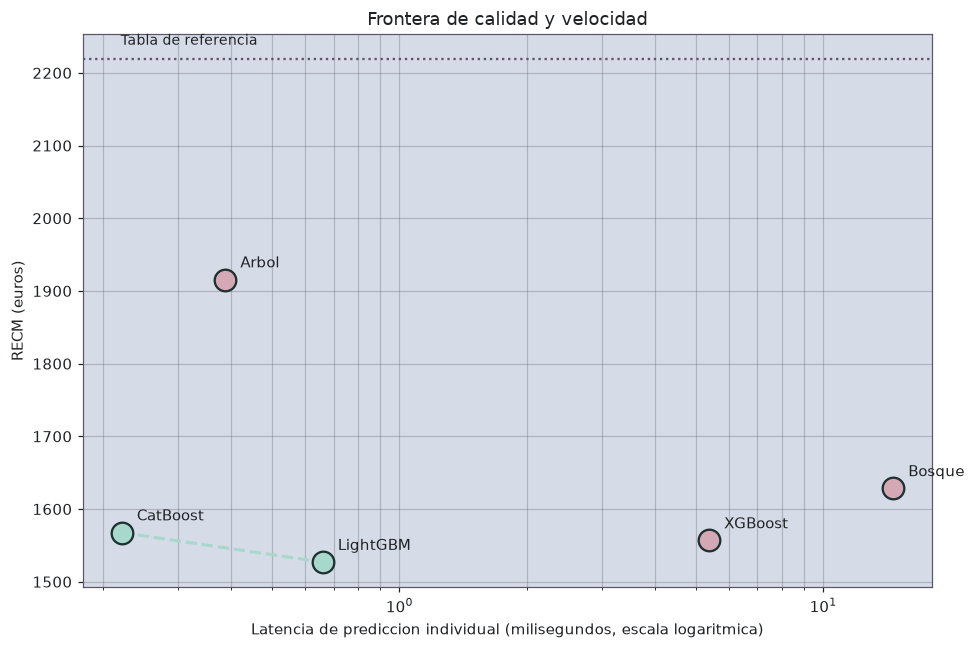

Modelos en la frontera:
  CatBoost -> RECM 1567.63 euros, latencia 0.221 ms
  LightGBM -> RECM 1527.02 euros, latencia 0.659 ms

Modelos dominados:
  XGBoost
  Bosque
  Arbol


In [46]:
frontera_datos = consolidado[consolidado["supera_referencia"]].copy()

def en_frontera(fila, tabla):
    dominado = (
        (tabla["recm_media"] <= fila["recm_media"]) &
        (tabla["latencia_individual_ms"] <= fila["latencia_individual_ms"]) &
        ((tabla["recm_media"] < fila["recm_media"]) | (tabla["latencia_individual_ms"] < fila["latencia_individual_ms"]))
    )
    return not dominado.any()

frontera_datos["en_frontera"] = frontera_datos.apply(
    lambda f: en_frontera(f, frontera_datos), axis=1
)

fig, ax = plt.subplots(figsize=(9, 6))

for _, f in frontera_datos.iterrows():
    color_punto = colores["ganador"] if f["en_frontera"] else colores["alerta"]
    ax.scatter(f["latencia_individual_ms"], f["recm_media"],
               s=200, color=color_punto, edgecolor=colores["neutro"],
               linewidth=1.5, zorder=3)
    ax.annotate(f["etiqueta"],
                (f["latencia_individual_ms"], f["recm_media"]),
                textcoords="offset points", xytext=(10, 8), fontsize=10)

pareto = frontera_datos[frontera_datos["en_frontera"]].sort_values("latencia_individual_ms")
ax.plot(pareto["latencia_individual_ms"], pareto["recm_media"],
        color=colores["ganador"], linewidth=2, linestyle="--", zorder=2)

ax.axhline(referencia, color=colores["rejilla"], linestyle=":", linewidth=1.5)
ax.text(0.22, referencia + 20, "Tabla de referencia", fontsize=9, color=colores["texto"])

ax.set_xscale("log")
ax.set_xlabel("Latencia de prediccion individual (milisegundos, escala logaritmica)")
ax.set_ylabel("RECM (euros)")
ax.set_title("Frontera de calidad y velocidad")
ax.grid(True, which="both")
plt.tight_layout()
plt.show()

print("Modelos en la frontera:")
for _, f in pareto.iterrows():
    print(" ", f["etiqueta"], "-> RECM", f"{f['recm_media']:.2f}", "euros, latencia", f"{f['latencia_individual_ms']:.3f}", "ms")

print()
print("Modelos dominados:")
for _, f in frontera_datos[~frontera_datos["en_frontera"]].iterrows():
    print(" ", f["etiqueta"])

La frontera se construye sobre las dos magnitudes que el encargo declara de interés y que entran
en conflicto: la calidad de la predicción, medida por la RECM, y la velocidad de la predicción,
medida por la latencia individual. Se emplea la latencia individual y no el tiempo de lote porque
corresponde al caso de uso descrito: una aplicación que responde consulta por consulta.

Un modelo pertenece a la frontera cuando ningún otro lo supera de forma simultánea en ambas
magnitudes. Los restantes quedan dominados y se descartan sin necesidad de argumentación
adicional, dado que existe una alternativa mejor en todos los aspectos considerados.

**La frontera queda integrada por dos modelos: CatBoost y LightGBM.**

Quedan dominados el árbol de decisión, el bosque aleatorio y XGBoost. Este último constituye el
caso más nítido: presenta peor RECM que LightGBM y una latencia ocho veces superior. No existe
criterio bajo el cual resulte preferible.

El bosque aleatorio queda descartado por su latencia de 14.622 milisegundos, la más alta del
conjunto, atribuida en la sección 10.3 al costo de reparto entre núcleos para una observación
aislada.

### 12.3 Regla de equivalencia entre modelos

In [47]:
candidatos = consolidado[consolidado["supera_referencia"]].reset_index(drop=True)

pares = []
for i in range(len(candidatos)):
    for j in range(i + 1, len(candidatos)):
        a = candidatos.iloc[i]
        b = candidatos.iloc[j]
        diferencia = abs(a["recm_media"] - b["recm_media"])
        umbral = min(a["recm_desv"], b["recm_desv"])
        pares.append({
            "modelo_a": a["etiqueta"],
            "modelo_b": b["etiqueta"],
            "diferencia_recm": diferencia,
            "umbral_desviacion": umbral,
            "equivalentes": diferencia < umbral,
        })

pares = pd.DataFrame(pares)
display(pares.round(2))

print()
print("Pares equivalentes:", int(pares["equivalentes"].sum()), "de", len(pares))

par_frontera = pares[
    ((pares["modelo_a"] == "LightGBM") & (pares["modelo_b"] == "CatBoost")) |
    ((pares["modelo_a"] == "CatBoost") & (pares["modelo_b"] == "LightGBM"))
].iloc[0]

print()
print("Par de la frontera")
print("  Diferencia:", f"{par_frontera['diferencia_recm']:.2f}", "euros")
print("  Umbral:", f"{par_frontera['umbral_desviacion']:.2f}", "euros")
print("  Equivalentes:", bool(par_frontera["equivalentes"]))

,modelo_a,modelo_b,diferencia_recm,umbral_desviacion,equivalentes
0,LightGBM,XGBoost,29.73,18.98,False
1,LightGBM,CatBoost,40.61,19.13,False
2,LightGBM,Bosque,101.41,18.22,False
3,LightGBM,Arbol,388.63,12.53,False
4,XGBoost,CatBoost,10.88,18.98,True
5,XGBoost,Bosque,71.69,18.22,False
6,XGBoost,Arbol,358.90,12.53,False
7,CatBoost,Bosque,60.80,18.22,False
8,CatBoost,Arbol,348.02,12.53,False
9,Bosque,Arbol,287.21,12.53,False



Pares equivalentes: 1 de 10

Par de la frontera
  Diferencia: 40.61 euros
  Umbral: 19.13 euros
  Equivalentes: False


La regla fijada en la sección 6.2 se aplica a los diez pares posibles entre los cinco modelos que
superan el umbral. Dos modelos se declaran equivalentes cuando la diferencia de RECM resulta
inferior a la desviación entre pliegues del mejor de ellos.

Nueve de los diez pares son distinguibles. El único par equivalente es XGBoost con CatBoost, con
10.88 euros de diferencia frente a un umbral de 18.98. Empatan en calidad, y entre ambos la
elección se resuelve por velocidad: 0.221 milisegundos de CatBoost frente a 5.376 de XGBoost.

**El par de la frontera no resulta equivalente.** La diferencia entre LightGBM y CatBoost es de
40.61 euros frente a un umbral de 19.13. LightGBM es superior en calidad de forma verificable, y
CatBoost es superior en velocidad de forma igualmente verificable. La regla no resuelve la
elección: se requiere el criterio de negocio.

### 12.4 Traducción del error a la escala del negocio

Resultados sobre el conjunto de prueba, no utilizado hasta este punto
  LightGBM: 1517.36 euros
  CatBoost: 1561.33 euros


,registros,precio_medio,recm_lgbm,recm_cb,error_relativo_lgbm_%,error_relativo_cb_%
rango,,,,,,
100 a 999,16684.0,598.5,998.5,999.2,166.8,167.0
1000 a 2499,19757.0,1656.8,915.3,933.3,55.2,56.3
2500 a 4999,18012.0,3595.1,1276.9,1296.0,35.5,36.1
5000 a 9999,16479.0,7238.1,1698.7,1757.6,23.5,24.3
10000 a 20000,10770.0,14156.6,2691.2,2795.1,19.0,19.7


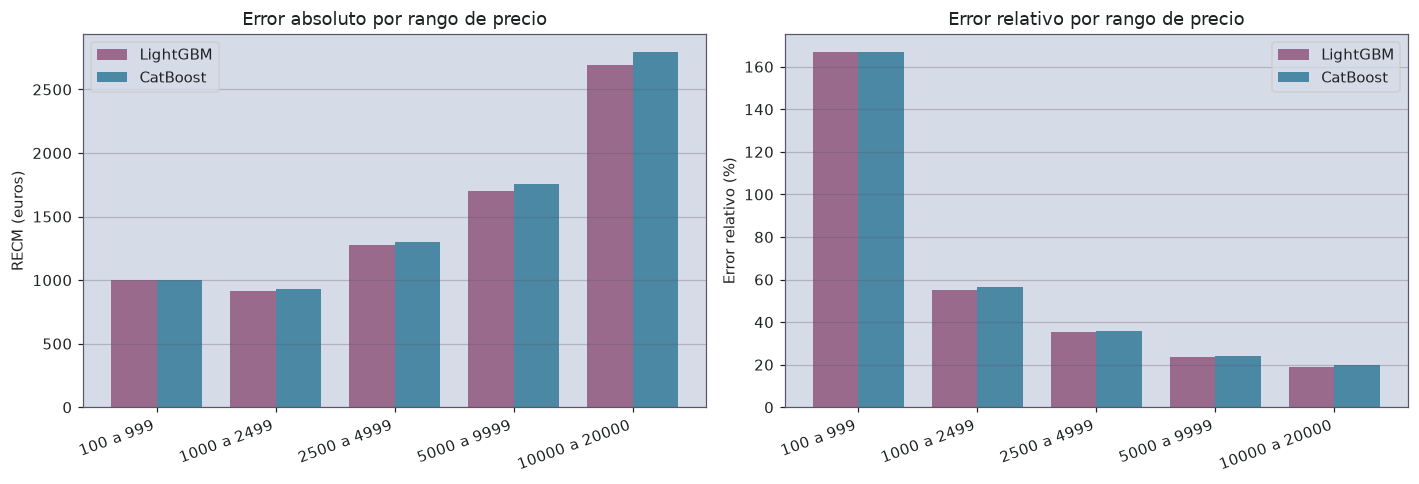

In [50]:
modelo_final_lgbm = lgb.LGBMRegressor(
    n_estimators=600, learning_rate=0.05, num_leaves=127,
    random_state=RANDOM_STATE, verbose=-1, n_jobs=-1,
).fit(X_arboles_train, y_train)

X_catboost_test = X_arboles_test.copy()
for c in columnas_cat_catboost:
    X_catboost_test[c] = X_catboost_test[c].astype(str)

modelo_final_cb = CatBoostRegressor(
    iterations=1000, learning_rate=0.05, depth=10,
    random_state=RANDOM_STATE, verbose=0, cat_features=columnas_cat_catboost,
).fit(X_catboost_train, y_train)

pred_lgbm = modelo_final_lgbm.predict(X_arboles_test)
pred_cb = modelo_final_cb.predict(X_catboost_test)

print("Resultados sobre el conjunto de prueba, no utilizado hasta este punto")
print("  LightGBM:", f"{recm(y_test, pred_lgbm):.2f}", "euros")
print("  CatBoost:", f"{recm(y_test, pred_cb):.2f}", "euros")

rangos = [100, 1000, 2500, 5000, 10000, 20001]
etiquetas_rango = ["100 a 999", "1000 a 2499", "2500 a 4999", "5000 a 9999", "10000 a 20000"]

analisis = pd.DataFrame({
    "precio_real": y_test.to_numpy(),
    "pred_lgbm": pred_lgbm,
    "pred_cb": pred_cb,
})
analisis["rango"] = pd.cut(analisis["precio_real"], bins=rangos, labels=etiquetas_rango, right=False)

por_rango = analisis.groupby("rango", observed=True).apply(
    lambda g: pd.Series({
        "registros": len(g),
        "precio_medio": g["precio_real"].mean(),
        "recm_lgbm": recm(g["precio_real"], g["pred_lgbm"]),
        "recm_cb": recm(g["precio_real"], g["pred_cb"]),
    }),
    include_groups=False,
)
por_rango["error_relativo_lgbm_%"] = (por_rango["recm_lgbm"] / por_rango["precio_medio"] * 100)
por_rango["error_relativo_cb_%"] = (por_rango["recm_cb"] / por_rango["precio_medio"] * 100)

display(por_rango.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(por_rango))
ancho = 0.38

axes[0].bar(x - ancho/2, por_rango["recm_lgbm"], ancho, color=colores["potenciacion"], label="LightGBM")
axes[0].bar(x + ancho/2, por_rango["recm_cb"], ancho, color=colores["apoyo"], label="CatBoost")
axes[0].set_xticks(x)
axes[0].set_xticklabels(por_rango.index, rotation=20, ha="right")
axes[0].set_ylabel("RECM (euros)")
axes[0].set_title("Error absoluto por rango de precio")
axes[0].legend()
axes[0].grid(True, axis="y")

axes[1].bar(x - ancho/2, por_rango["error_relativo_lgbm_%"], ancho, color=colores["potenciacion"], label="LightGBM")
axes[1].bar(x + ancho/2, por_rango["error_relativo_cb_%"], ancho, color=colores["apoyo"], label="CatBoost")
axes[1].set_xticks(x)
axes[1].set_xticklabels(por_rango.index, rotation=20, ha="right")
axes[1].set_ylabel("Error relativo (%)")
axes[1].set_title("Error relativo por rango de precio")
axes[1].legend()
axes[1].grid(True, axis="y")

plt.tight_layout()
plt.show()

La RECM constituye una magnitud absoluta que trata por igual un error de quinientos euros en un
vehículo de ochocientos y en uno de treinta mil. Para decidir se requiere el error relativo por
rango de precio.

El análisis se realiza sobre el conjunto de prueba, no utilizado hasta este punto. LightGBM
alcanza 1 517.36 euros y CatBoost 1 561.33, cifras inferiores a las obtenidas en validación
cruzada por diez y seis euros respectivamente, diferencias contenidas en el ruido de veinte euros.
No existe indicio de sobreajuste al procedimiento de selección.

**El error relativo invierte la lectura del error absoluto.** En el rango de 100 a 999 euros el
error absoluto es el menor de los cinco, con 998.5 euros, pero representa 166.8 % del precio medio
de 598.5 euros: el modelo predice, en promedio, más del doble del valor real. En el rango de
10 000 a 20 000 euros el error absoluto casi se triplica hasta 2 691.2 euros, si bien equivale
únicamente a 19.0 % del precio medio.

La causa reside en la métrica. El error cuadrático medio penaliza el cuadrado de la desviación, de
modo que un fallo de dos mil euros pesa cuatro veces más que uno de mil. El procedimiento de
ajuste concentra su capacidad donde la métrica castiga con mayor severidad y desatiende el extremo
inferior de la distribución.

Es el efecto anticipado en la sección 3.5 al resolver que la variable objetivo se modelara en
euros y no en escala logarítmica. La decisión resulta correcta dada la métrica impuesta por el
encargo, pero su costo sobre el segmento de vehículos económicos queda documentado y se retoma en
la sección 13.

Entre los dos modelos de la frontera, LightGBM presenta menor error relativo en los cinco rangos.
La diferencia es de 0.2 puntos porcentuales en el rango más bajo y de 0.8 en el más alto.

## 13. Conclusiones y recomendación

**Recomendación: LightGBM con seiscientos árboles, tasa de aprendizaje 0.05 y ciento veintisiete
hojas.**

El fundamento es que la única magnitud en la que CatBoost lo aventaja carece de relevancia
operativa a la escala del encargo. La diferencia de latencia individual entre ambos es de 0.438
milisegundos. Una aplicación que consulta un servicio remoto incurre en latencias de red de entre
cincuenta y doscientos milisegundos, de modo que la diferencia entre los dos modelos representa
menos del uno por ciento del tiempo que el usuario percibe. No es un criterio de decisión.

La ventaja de LightGBM en calidad, en cambio, sí es material: 40.61 euros de RECM frente a un
umbral de distinguibilidad de 19.13, y menor error relativo en los cinco rangos de precio.

A ello se suma el comportamiento ante el crecimiento del conjunto. LightGBM presenta el exponente
de escalamiento más bajo de los cinco modelos evaluados, con 0.058, frente a 0.782 de CatBoost.
Ante un conjunto de diez millones de registros, la extrapolación sitúa el reentrenamiento en trece
segundos para LightGBM y en quince minutos para CatBoost. La ventaja se amplía conforme crece el
inventario de Rusty Bargain.

**Salvedad sobre el procesamiento por lotes.** Si el uso principal fuese la revaluación periódica
del inventario completo en lugar de la consulta individual, la recomendación se invertiría.
CatBoost procesa 49 021 registros en 54.7 milisegundos frente a 241.8 de LightGBM, con una razón
de 4.4 a favor de CatBoost. Se recomienda mantener ambos modelos disponibles si se prevén los dos
escenarios de uso.

**Cuantificación de la mejora frente al proceso actual.** La tabla de referencia por marca, modelo
y antigüedad alcanza 2 218.66 euros de RECM. LightGBM alcanza 1 517.36 euros sobre el conjunto de
prueba. La reducción es de 701.3 euros, equivalentes a 31.6 %, a cambio de un tiempo de
entrenamiento que pasa de dieciocho milisegundos a once segundos y de una latencia de predicción
que se reduce de 0.925 a 0.659 milisegundos.

**Advertencia sobre el segmento de vehículos económicos.** El modelo recomendado presenta un error
relativo de 166.8 % en el rango de 100 a 999 euros, que agrupa 16 684 registros del conjunto de
prueba, equivalentes al 20.4 % del total. En ese segmento la estimación no es utilizable como
referencia de precio. Se recomienda que la aplicación no muestre valuación por debajo de un umbral
determinado, o que muestre un rango en lugar de un valor puntual. La causa es la métrica impuesta,
no un defecto del ajuste: el error cuadrático medio concentra la capacidad del modelo en el
extremo superior de la distribución.

**Sobre los tres criterios declarados por el cliente.** El encargo solicitó atender calidad de
predicción, velocidad de predicción y tiempo de entrenamiento de forma simultánea. Las mediciones
muestran que los tres no admiten optimización conjunta: el modelo de mayor calidad es el más lento
por lote, el más rápido por lote es el más lento de entrenar, y el más rápido de entrenar es el de
peor calidad entre los métodos de potenciación. La frontera de la sección 12.2 reduce las
alternativas defendibles a dos, y la elección entre ellas depende del patrón de uso previsto.

## 14. Limitaciones y trabajo futuro

### Limitaciones

**Uno. Estimación optimista por duplicación.** El conjunto contiene 27 543 registros coincidentes
en características del vehículo y precio, equivalentes al 7.77 % del total original. Al conservarse,
ejemplares equivalentes quedan repartidos entre pliegues y entre las particiones de entrenamiento y
prueba, lo que favorece a los modelos con mayor capacidad de memorización. El efecto opera por igual
sobre todos los procedimientos comparados, de modo que no altera el orden relativo, pero las cifras
absolutas de RECM constituyen una estimación optimista del desempeño sobre vehículos no observados.

**Dos. Alcance de la extrapolación.** La proyección a diez millones de registros de la sección 11.3
cubre un factor de cuarenta y uno por encima del rango medido. Presupone que la memoria disponible
resulta suficiente, que ninguna constante cambia de régimen y que la forma de potencia se mantiene.
Es orientación de magnitud, no predicción.

**Tres. Mediciones de tiempo dependientes del equipo.** Las magnitudes temporales se obtuvieron en
una máquina concreta, con paralelización activada sobre todos los núcleos disponibles. Las razones
entre modelos son transferibles; los valores absolutos no.

**Cuatro. Ausencia de validación temporal.** Las particiones son aleatorias. El conjunto abarca dos
meses de captura, lapso que no permite evaluar la estabilidad del modelo ante desplazamientos del
mercado. Un modelo ajustado sobre precios de 2016 no es aplicable sin reentrenamiento en un mercado
posterior.

**Cinco. Truncamiento de la variable objetivo.** El precio se encuentra recortado en veinte mil
euros. Las conclusiones no son extensibles a vehículos por encima de ese valor.

**Seis. Discretización del kilometraje.** La variable `Mileage` presenta mediana, tercer cuartil y
máximo coincidentes en 150 000 kilómetros. No es una magnitud continua sino una escala truncada y
discretizada en el origen, circunstancia que limita su poder discriminante en el extremo superior.

**Siete. Ambigüedad en las categorías de combustible.** La variable `FuelType` distingue `gasoline`
y `petrol`, denominaciones equivalentes en las variantes estadounidense y británica del inglés. No
se unificaron por no disponer de documentación que confirme la equivalencia en el origen de los
datos.

**Ocho. Barrido de hiperparámetros acotado.** Las configuraciones exploradas fueron ocho para
LightGBM, seis para XGBoost y cuatro para CatBoost, seleccionadas por diagnóstico dirigido y no por
búsqueda exhaustiva. Una exploración sistemática podría mejorar los resultados, si bien las curvas
alcanzaron meseta en los tres casos.

### Trabajo futuro

**Aprovechamiento de la información geográfica.** La variable `PostalCode` se descartó en la sección
5.5 por su cardinalidad de aproximadamente ocho mil valores. Su explotación correcta requeriría
agregación regional o codificación por objetivo, esta última con riesgo de fuga si se calcula antes
de particionar. El procedimiento admisible consiste en calcular las estadísticas dentro de cada
pliegue de entrenamiento.

**Modelo por segmento de precio.** El error relativo de 166.8 % en el rango inferior sugiere ajustar
un modelo específico para vehículos económicos, evaluado con una métrica sensible al error relativo.

**Predicción por intervalo.** La aplicación entrega un valor puntual. Un intervalo de confianza
resultaría más informativo para el usuario y permitiría comunicar la incertidumbre del segmento
inferior en lugar de ocultarla.

**Validación temporal.** Disponiendo de un historial más extenso, particionar por fecha en lugar de
al azar permitiría evaluar la degradación del modelo con el transcurso del tiempo y determinar la
periodicidad de reentrenamiento.

**Reducción del número de árboles en LightGBM.** El tiempo de predicción por lote de 241.8
milisegundos es el más alto del conjunto y resulta proporcional al número de árboles. Un análisis de
parada temprana sobre el conjunto de validación permitiría determinar cuántos de los seiscientos
árboles aportan mejora efectiva.

## 15. Anexo A. Acotaciones de símbolos y sintaxis

### Símbolos y notación

**RECM.** Raíz del error cuadrático medio. Se lee: raíz cuadrada de la media de los cuadrados de las
diferencias entre valor observado y valor predicho.

    RECM = √( (1/n) · Σ (yᵢ − ŷᵢ)² )

donde `n` es el número de observaciones, `yᵢ` el precio observado de la observación i-ésima, `ŷᵢ` el
precio predicho para esa misma observación, y `Σ` la suma sobre todas las observaciones desde i igual
a uno hasta n. La raíz cuadrada devuelve el resultado a la unidad original, el euro.

**ECM.** Error cuadrático medio. Es la RECM sin la raíz. La constante que lo minimiza es la media de
la variable objetivo; para el error absoluto medio, la constante minimizadora es la mediana.

**T(n).** Tiempo de ejecución en función del número de registros. Se lee: te de ene.

**T(n) = c · n^k.** Relación de potencia entre tiempo y tamaño. `c` es la constante de
proporcionalidad, que absorbe el costo por unidad de trabajo y depende de la máquina; `k` es el
exponente de escalamiento, que caracteriza el algoritmo. Tomando logaritmos:

    log T = log c + k · log n

de donde `k` es la pendiente de la recta en escala logarítmica doble y `log c` su ordenada al origen.

**cond(X).** Número de condición de la matriz X. Cuantifica la sensibilidad de la solución de un
sistema lineal ante perturbaciones en los datos. Al formar la ecuación normal se cumple

    cond(XᵀX) = cond(X)²

de modo que un mal condicionamiento en X se agrava al cuadrado.

**Xᵀ.** Transpuesta de la matriz X. Se lee: equis transpuesta. Intercambia filas por columnas.

**η.** Letra griega eta. Tasa de aprendizaje en los métodos de potenciación. Escala la contribución
de cada árbol al conjunto. Se relaciona con el número de árboles `N` mediante el canje aproximado
`η × N`, que tiende a conservarse: reducir la tasa a la mitad exige aproximadamente duplicar los
árboles para alcanzar un ajuste equivalente.

**R².** Coeficiente de determinación. Proporción de la varianza explicada por el ajuste. Un valor de
uno indica ajuste perfecto.

**p.** Número de columnas o características de la matriz de diseño.

### Sintaxis y elementos de código

**`time.perf_counter()`.** Reloj monótono de alta resolución, destinado a medir intervalos. Se
prefiere sobre `time.time()`, que puede retroceder si el sistema ajusta la hora.

**`KFold(n_splits=5, shuffle=True, random_state=...)`.** Divide el conjunto en cinco partes iguales.
`shuffle` baraja antes de dividir, necesario cuando los registros conservan un orden original.

**`random_state`.** Semilla del generador pseudoaleatorio. Fijarla garantiza que la ejecución sea
reproducible. En este trabajo vale 12345 y se declara en un único lugar.

**`n_jobs=-1`.** Emplea todos los núcleos disponibles. Acelera el ajuste y la predicción por lote,
pero encarece la predicción de una observación aislada, dado que el reparto entre núcleos cuesta más
que el cálculo.

**`tree_method="hist"`.** Indica a XGBoost que emplee el método de histogramas, que discretiza cada
característica en contenedores antes de buscar cortes.

**`num_leaves` frente a `max_depth`.** LightGBM desarrolla los árboles por hoja, expandiendo
únicamente donde existe ganancia, y se controla por `num_leaves`. XGBoost y CatBoost los desarrollan
por nivel y se controlan por profundidad. Un árbol de profundidad `d` admite hasta `2^d` hojas: la
correspondencia aproximada entre ciento veintisiete hojas y profundidad siete se apoya en esa
relación.

**`cat_features`.** Argumento de CatBoost que declara qué columnas son categóricas. Exige que no
contengan valores ausentes.

**`drop_first=True`.** En la codificación indicadora, descarta una categoría por variable. Sin ese
descarte, la suma de las columnas de una misma variable vale uno para toda observación y reproduce la
columna de intercepto, lo que hace singular a XᵀX.

**`astype("category")`.** Convierte una columna de texto al tipo categórico de pandas, condición
necesaria para que LightGBM la procese de forma nativa.

**`observed=True`.** En una agrupación sobre columnas categóricas, restringe el resultado a las
combinaciones presentes en los datos. Sin él, pandas genera todas las combinaciones posibles del
producto cartesiano.

**`ddof=1`.** En el cálculo de la desviación estándar, divide entre n − 1 en lugar de n. Corresponde
a la estimación muestral, apropiada para los cinco valores de una validación cruzada.

## 16. Anexo B. Erratas del material del curso

Registro de discrepancias verificables entre el material del curso y el comportamiento observado en
el entorno de trabajo. Se consignan con carácter objetivo y con la referencia correspondiente.

**S15-01. Requisito de codificación indicadora para XGBoost.**

El enunciado del proyecto afirma: la codificación de características categóricas para algoritmos
simples debe atenderse, señalando que LightGBM y CatBoost tienen su implementación, pero XGBoost
requiere OHE.

La afirmación no se corresponde con las versiones vigentes de la librería. XGBoost admite variables
categóricas de forma nativa desde la versión 1.5, mediante el argumento `enable_categorical=True`
en combinación con `tree_method="hist"`. La versión empleada en este trabajo es la 3.2.0.

El presente proyecto conserva la codificación indicadora para XGBoost por dos motivos: cumplir la
instrucción del encargo, y establecer el contraste controlado entre representaciones que sustenta
el análisis de las secciones 5.5 y 9.2. La discrepancia se consigna sin que altere los resultados.

**S15-02. Argumento `squared` de `mean_squared_error`.**

El material del curso obtiene la RECM mediante `mean_squared_error(y_real, y_pred, squared=False)`.
Ese argumento fue declarado obsoleto en scikit-learn 1.4 y retirado en versiones posteriores. La
versión empleada en este trabajo es la 1.9.0, en la cual el argumento no existe.

Las alternativas vigentes son `root_mean_squared_error`, disponible desde la versión 1.4, o el
cálculo explícito de la raíz cuadrada del error cuadrático medio. Este trabajo adopta la segunda
por no depender de la versión instalada.

**S15-03. Tipo de dato de las columnas de texto.**

El material del curso identifica las columnas de texto con el tipo `object` al inspeccionar un
marco de datos mediante `info()`. En pandas 3.0.5, versión empleada en este trabajo, las columnas de
texto se identifican con el tipo `str`, tipo nativo introducido en esa versión.

La diferencia tiene consecuencia práctica sobre el consumo de memoria: el conjunto ocupa 43.3 MB con
el tipo `str`, frente a los 214 MB que reportó la medición con `deep=True` sobre la representación
anterior. Toda selección de columnas basada en `select_dtypes(include="object")` deja de funcionar.

**S15-04. Dependencia no documentada de LightGBM en macOS.**

La instalación de LightGBM mediante `pip` en macOS con arquitectura ARM no incluye la biblioteca de
paralelización OpenMP, cuya ausencia impide la importación del módulo. El material del curso no
consigna este requisito.

La resolución consiste en instalar `llvm-openmp` desde el canal conda-forge. Se advierte que el
paquete `libomp`, denominación empleada por Homebrew, no existe en dicho canal.

**S15-05. Comportamiento de `groupby().apply()` sobre columnas de agrupación.**

En pandas 3.0, el método `apply` aplicado sobre un objeto agrupado exige la especificación explícita
del argumento `include_groups`. Su omisión produce advertencia y, en construcciones que operan sobre
las columnas de agrupación, comportamiento distinto al de versiones anteriores.

**S15-06. Ausencia de umbral en los criterios de velocidad.**

El enunciado declara tres criterios de interés del cliente —calidad de la predicción, velocidad de
la predicción y tiempo requerido para el entrenamiento— sin asignar umbral numérico a ninguno, ni
indicar el procedimiento para establecerlos.

La omisión impide evaluar el cumplimiento de dos de los tres criterios declarados. Este trabajo fija
los umbrales como supuestos de diseño en la sección 1.4, con su justificación correspondiente, y los
declara expresamente como tales y no como requisitos del cliente.

## 17. Lista de control

- [ ] Jupyter Notebook está abierto
- [ ] El código no tiene errores
- [ ] Las celdas con el código han sido colocadas en orden de ejecución
- [ ] Los datos han sido descargados y preparados
- [ ] Los modelos han sido entrenados
- [ ] Se realizó el análisis de velocidad y calidad de los modelos

## 18. Contacto

## 18. Contacto y recursos del proyecto

---

| Recurso | Enlace |
|---|---|
| 📦 Repositorio | [github.com/he1109-ci3l0/rusty-bargain-precio-vehiculos](https://github.com/he1109-ci3l0/rusty-bargain-precio-vehiculos) |
| 📊 Case study (web) | [he1109-ci3l0.github.io/rusty-bargain-precio-vehiculos](https://he1109-ci3l0.github.io/rusty-bargain-precio-vehiculos/) |
| 🧩 Código modular | [`src/`](https://github.com/he1109-ci3l0/rusty-bargain-precio-vehiculos/tree/master/src) |
| 📈 Figuras | [`figures/`](https://github.com/he1109-ci3l0/rusty-bargain-precio-vehiculos/tree/master/figures) |
| 🧪 Entorno reproducible | `environment.yml` (conda: `rusty-bargain`, Python 3.11) |
| 📁 Datos | TripleTen — `car_data.csv`, 354 369 registros |

---

**Belem Cisneros Díaz** — Data scientist y consultora independiente. Ciudad de México.

*Proyecto desarrollado como parte del bootcamp de Data Science de TripleTen. Sprint 15 — Métodos
numéricos. Métrica oficial: RECM sobre `Price`. Modelo recomendado: LightGBM, RECM de 1 517.36 euros
sobre el conjunto de prueba.*